In [125]:
import pandas as pd                     # 데이터프레임 처리
import numpy as np                      # 수치 연산
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split          # train/test 분할
from sklearn.compose import ColumnTransformer                 # 컬럼별로 다른 전처리 적용
from sklearn.preprocessing import OneHotEncoder, StandardScaler  # 범주형 인코딩 / 수치형 스케일링
from sklearn.pipeline import Pipeline                         # 전처리 + 모델을 하나로 묶음

from sklearn.linear_model import LogisticRegression           # baseline 모델 1
from sklearn.tree import DecisionTreeClassifier               # baseline 모델 2
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score,   # average_precision = PR-AUC
                             confusion_matrix, classification_report, precision_recall_curve)
from sklearn.base import BaseEstimator, TransformerMixin
import time                                # 모델별 튜닝 시간 측정용
from sklearn.model_selection import GridSearchCV, StratifiedKFold   # 하이퍼파라미터 탐색 / 클래스 비율 유지 K-Fold
from sklearn.base import clone                              # 튜닝된 모델의 파라미터만 복사 (학습 결과는 제외)
from imblearn.pipeline import Pipeline as ImbPipeline       # 샘플링 단계를 넣을 수 있는 Pipeline
from imblearn.under_sampling import RandomUnderSampler      # RUS
from imblearn.over_sampling import SMOTENC                  # SMOTE-NC (수치형 + 범주형 혼합 데이터용)

# 컬럼이 많아도 '...'으로 생략하지 않고 전부 표시
pd.set_option("display.max_columns", None)
# 표가 옆으로 길어져도 줄바꿈 없이 한 줄로 표시
pd.set_option("display.width", None)

# 그래프 한글 깨짐 방지 (Windows: 맑은 고딕)
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False     # 음수 부호(-) 깨짐 방지

### 데이터 로드 & 타깃 변환시키기

In [40]:
RANDOM_STATE = 42   # 재현성을 위한 시드 (분할, 모델 모두 동일하게 사용)

# utf-8-sig: 파일 맨 앞의 BOM 문자를 제거
# (안 하면 첫 컬럼명이 'age'가 아니라 '\ufeffage'로 읽힘)
df = pd.read_csv("add_bank.csv", encoding="utf-8-sig")

# 타깃을 yes → 1, no → 0 으로 변환
# precision/recall 등의 지표는 기본적으로 1(양성)을 기준으로 계산되므로
# 우리가 관심 있는 '가입(yes)'을 1로 둔다
df["y"] = (df["y"] == "yes").astype(int)

# 클래스 비율 확인 → no 88.3% / yes 11.7% 의 불균형 데이터
df["y"].value_counts(normalize=True)

y
0    0.883015
1    0.116985
Name: proportion, dtype: float64

In [ ]:
# 월별 상담 건수: 같은 연도-월에 상담한 고객 수 (캠페인 강도를 나타내는 변수)
# - groupby로 연도-월별 그룹을 만들고, 그룹의 행 개수(size)를 각 행에 붙임
# - transform은 컬럼을 하나 지정해야 해서 그룹 기준인 'month'를 지정
#   (값을 쓰는 게 아니라 행 개수만 세므로 어떤 컬럼을 지정해도 결과는 같음)
# - y(가입 여부)는 사용하지 않으므로 데이터 누수 없음
df["month_contacts"] = df.groupby(["year", "month"])["month"].transform("size")

# 확인: 연도-월마다 같은 값이 붙었는지
display(df.groupby(["year", "month"], sort=False)["month_contacts"].first().head(10))

year  month
2008  may      7957
      jun      4486
      jul      6380
      aug      5215
      oct        80
      nov      3598
      dec        13
2009  jan      1176
      feb      2296
      mar       258
Name: month_contacts, dtype: int64

In [78]:
df.columns

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'y', 'age_group', 'year', 'balance_group'],
      dtype='str')

### 피처 정의

In [93]:
# 수치형 변수
# - duration 제외: 통화가 끝나야 알 수 있는 값이라 사전 예측에 쓰면 데이터 누수
# - month_contacts 추가: 해당 월의 상담 건수 (year 대신 캠페인 강도를 반영)
num_cols = ["age", "balance", "day", "campaign", "pdays", "previous",
            "month_contacts"]

# 범주형 변수 → 이후 One-Hot Encoding 적용
# - year 제외: 미래 연도는 학습 때 본 적 없는 값이라 예측에 쓸 수 없고,
#   고객 특성이 아니라 '데이터의 시점'을 외우는 변수라서 제외
#   (df에는 남겨 두어 시간순 분할, 기간별 분석에는 계속 사용)
# - age_group, balance_group: 성능 향상을 위해 생성한 파생 변수
cat_cols = ["job", "marital", "education", "default", "housing", "loan",
            "contact", "month", "poutcome",
            "age_group", "balance_group"]

X = df[num_cols + cat_cols].copy()   # copy(): 원본 df가 바뀌지 않도록 복사
y = df["y"]

### Train/Validation/Test 분할

In [94]:
# 비율: train 60% / validation 20% / test 20%
# - train     : 모델 학습
# - validation: 불균형 처리 방법 비교, 하이퍼파라미터 튜닝, 임계값 결정
# - test      : 최종 선택된 모델을 마지막에 '한 번만' 평가 (중간에 보면 안 됨)

# 1단계: 전체에서 test 20%를 먼저 떼어냄
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,                  # yes 비율 11.7% 유지
    random_state=RANDOM_STATE)

# 2단계: 남은 80%를 train과 validation으로 나눔
# 남은 80% 중 25%를 validation으로 → 전체 기준 0.8 × 0.25 = 20%
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.25,
    stratify=y_temp,             # 여기서도 stratify 필수 (y가 아니라 y_temp 기준)
    random_state=RANDOM_STATE)

# 크기와 yes 비율 확인 → 세 세트 모두 약 11.7%여야 정상
for name, target in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name:5s} | 행 수: {len(target):6d} | yes 비율: {target.mean():.4f}")

train | 행 수:  27126 | yes 비율: 0.1170
val   | 행 수:   9042 | yes 비율: 0.1170
test  | 행 수:   9043 | yes 비율: 0.1170


### 전처리 & 모델 정의

In [95]:
# handle_unknown="ignore": test에만 있는 범주가 나와도 에러 없이 0으로 처리
ohe = OneHotEncoder(handle_unknown="ignore")

# Logistic Regression용 전처리
# - 수치형: StandardScaler로 평균 0, 표준편차 1로 맞춤
#   (LR은 변수 스케일에 민감함. balance처럼 값이 큰 변수가 학습을 지배하는 것을 방지)
# - 범주형: One-Hot Encoding
prep_lr = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", ohe, cat_cols),
])

# Tree용 전처리
# - 수치형: 원본 그대로 유지
# - 범주형: OneHotEncoder
# - 트리는 '어떤 값보다 큰가/작은가'로만 분기하므로 스케일링이 필요 없음 → passthrough
prep_dt = ColumnTransformer([
    ("num", "passthrough", num_cols),
    ("cat", ohe, cat_cols),
])


### 모델별 탐색 공간  만들기
> 형식: '모델이름': (모델 또는 파이프라인, 탐색할 파라미터 후보) <br>
>불균형 처리 전이므로 class_weight, scale_pose_weight 등은 넣지 않는다.

In [96]:
# 형식: "모델이름": (모델 또는 파이프라인, 탐색할 파라미터 후보)
# - 불균형 처리 전이므로 class_weight, scale_pos_weight 등은 넣지 않음
# - 목적은 '최고 성능'이 아니라 망가지지 않은 공정한 baseline이므로 후보는 적게 잡음
search_space = {
    "LogisticRegression": (
        Pipeline([("prep", prep_lr),
                  ("clf", LogisticRegression(max_iter=1000))]),
        # C: 규제 강도의 역수. 작을수록 규제가 강해져 계수가 작아짐 (과적합 방지)
        {"clf__C": [0.01, 0.1, 1, 10]},
    ),
    "DecisionTree": (
        Pipeline([("prep", prep_dt),
                  ("clf", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
        # max_depth: 트리의 최대 깊이 (None = 제한 없음)
        # min_samples_leaf: 리프 하나에 필요한 최소 샘플 수
        # - 이 데이터는 깊이 제한만으로는 과적합이 잘 안 잡히고
        #   min_samples_leaf가 과적합 방지에 더 크게 작용하므로 범위를 넓게 탐색
        # - 깊이 제한 없는 트리(None, 1)는 train에 과적합되어
        #   예측 확률이 0/1만 나오는 문제가 있었으므로, 이를 막는 값들을 충분히 포함
        {"clf__max_depth": [3, 5, 7, 10, 15, None],
         "clf__min_samples_leaf": [1, 20, 50, 100, 150, 200, 300]},
    ),
    "RandomForest": (
        Pipeline([("prep", prep_dt),
                  ("clf", RandomForestClassifier(n_estimators=300,      # 트리 개수 (많을수록 안정적, 느려짐)
                                                 random_state=RANDOM_STATE,
                                                 n_jobs=-1))]),         # CPU 코어 모두 사용
        {"clf__max_depth": [10, 20, None],
         "clf__min_samples_leaf": [1, 5, 20]},
    ),
    "XGBoost": (
        Pipeline([("prep", prep_dt),
                  ("clf", XGBClassifier(n_estimators=300,
                                        eval_metric="logloss",          # 학습 중 경고 메시지 방지
                                        random_state=RANDOM_STATE,
                                        n_jobs=-1))]),
        # max_depth: 부스팅은 얕은 트리 여러 개를 쌓는 방식이라 3~7 정도가 일반적
        # learning_rate: 트리 하나가 반영되는 정도. 작을수록 천천히, 안정적으로 학습
        {"clf__max_depth": [3, 5, 7],
         "clf__learning_rate": [0.05, 0.1]},
    ),
    "LightGBM": (
        Pipeline([("prep", prep_dt),
                  ("clf", LGBMClassifier(n_estimators=300,
                                         random_state=RANDOM_STATE,
                                         verbose=-1,                    # 학습 로그 출력 끄기
                                         n_jobs=-1))]),
        # num_leaves: LightGBM은 깊이 대신 리프 개수로 복잡도를 조절
        {"clf__num_leaves": [15, 31, 63],
         "clf__learning_rate": [0.05, 0.1]},
    ),
}

In [97]:
# 하이퍼파라미터 튜닝에 사용할 5-fold 교차검증 방식
# - StratifiedKFold: 5개 fold 모두 yes 비율 11.7%를 유지하며 나눔
#   (일반 KFold를 쓰면 어떤 fold에는 yes가 너무 적게 들어갈 수 있음)
# - shuffle=True: 원본 데이터가 연도순(2008→2010)으로 정렬되어 있으므로 섞은 뒤 나눔
# - random_state: 매번 같은 방식으로 나뉘도록 고정 → 모델 간 공정한 비교
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

In [98]:
best_models = {}    # 모델별 최적 파라미터로 학습된 모델 저장
tuning_log = []     # 모델별 튜닝 결과 기록
base_searches = {}  # 모델별 GridSearchCV 객체 저장 (탐색 과정 전체 포함)


for name, (estimator, grid) in search_space.items():
    start = time.time()

    search = GridSearchCV(
        estimator,
        grid,
        scoring="average_precision",   # PR-AUC 기준으로 최적 조합 선택
        cv=cv,                         # ⑤-1에서 정의한 StratifiedKFold(5-fold)
        n_jobs=1,                      # 병렬 처리는 모델 내부(n_jobs=-1)에서 하므로 여기선 1
        return_train_score=True,       # train fold 점수도 기록 (과적합 확인용 그래프에 사용)
    )

    # fit할 때 모델에 추가로 넘겨줄 인자
    # - CatBoost만 어떤 컬럼이 범주형인지 알려줘야 함
    # - 나머지 모델은 Pipeline의 원핫인코딩이 처리하므로 추가 인자 없음
    # - GridSearchCV.fit에 넣은 인자는 매 fold의 모델 학습에 그대로 전달됨
    fit_params = {"cat_features": cat_cols} if name == "CatBoost" else {}

    search.fit(X_train, y_train, **fit_params)   # train 데이터로만 탐색

    best_models[name] = search.best_estimator_   # 최적 파라미터로 train 전체에 다시 학습된 모델
    base_searches[name]=search
    tuning_log.append({
        "model": name,
        "best_params": search.best_params_,
        "cv_pr_auc": round(search.best_score_, 4),
        "time_sec": round(time.time() - start, 1),
    })
    print(f"{name:20s} 완료 | CV PR-AUC: {search.best_score_:.4f} | {time.time() - start:.0f}초")

LogisticRegression   완료 | CV PR-AUC: 0.4394 | 2초
DecisionTree         완료 | CV PR-AUC: 0.4361 | 38초
RandomForest         완료 | CV PR-AUC: 0.4560 | 79초
XGBoost              완료 | CV PR-AUC: 0.4639 | 10초
LightGBM             완료 | CV PR-AUC: 0.4614 | 13초


In [99]:
def clean_name(param):
    """'clf__max_depth' → 'max_depth' (Pipeline 단계 이름 제거)"""
    return param.replace("clf__", "")


rows = []
for name, search in base_searches.items():
    for p, values in search.param_grid.items():
        rows.append({
            "모델": name,
            "파라미터": clean_name(p),
            "탐색한 값": ", ".join(str(v) for v in values),   # search_space에 넣었던 후보들
            "선택된 값": search.best_params_[p],              # CV PR-AUC가 가장 높았던 값
            "조합 수": len(search.cv_results_["params"]),     # 이 모델에서 시험한 전체 조합 수
            "최적 CV PR-AUC": round(search.best_score_, 4),
        })

print("[처리 전 튜닝: 탐색한 값과 선택된 값]")
display(pd.DataFrame(rows).set_index(["모델", "파라미터"]))

[처리 전 튜닝: 탐색한 값과 선택된 값]


탐색한 값   선택된 값  \
모델                 파라미터                                                      
LogisticRegression C                              0.01, 0.1, 1, 10    0.10   
DecisionTree       max_depth                 3, 5, 7, 10, 15, None     NaN   
                   min_samples_leaf  1, 20, 50, 100, 150, 200, 300  150.00   
RandomForest       max_depth                          10, 20, None   20.00   
                   min_samples_leaf                       1, 5, 20    5.00   
XGBoost            max_depth                               3, 5, 7    3.00   
                   learning_rate                         0.05, 0.1    0.05   
LightGBM           num_leaves                           15, 31, 63   15.00   
                   learning_rate                         0.05, 0.1    0.05   

                                     조합 수  최적 CV PR-AUC  
모델                 파라미터                                  
LogisticRegression C                    4        0.4394  
DecisionTree       max_depth           42        0.4361  
                   min_samples_leaf    42        0.4361  
RandomForest       max_depth            9        0.4560  
                   min_samples_leaf     9        0.4560  
XGBoost            max_depth            6        0.4639  
                   learning_rate        6        0.4639  
LightGBM           num_leaves           6        0.4614  
                   learning_rate        6        0.4614

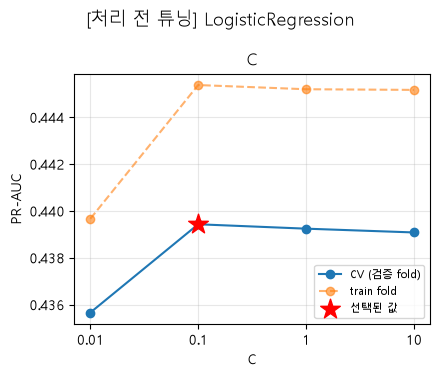

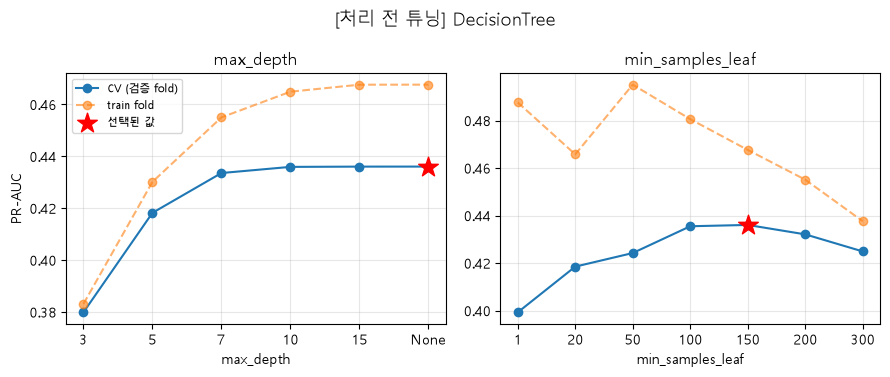

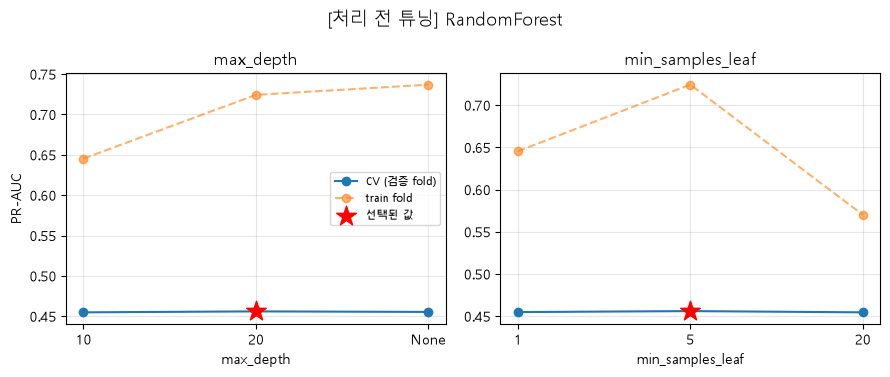

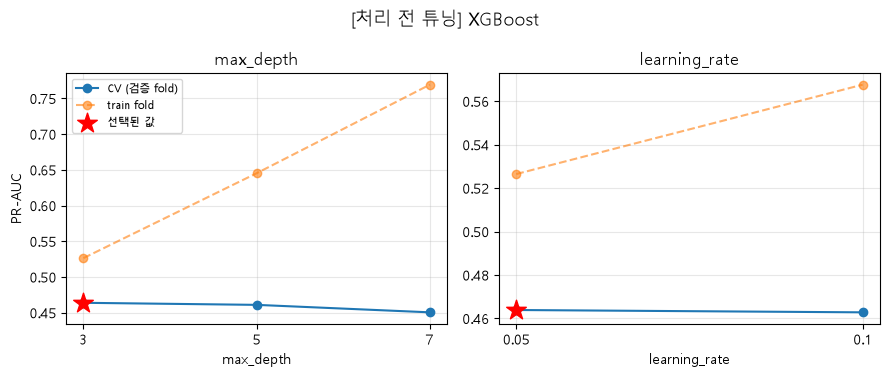

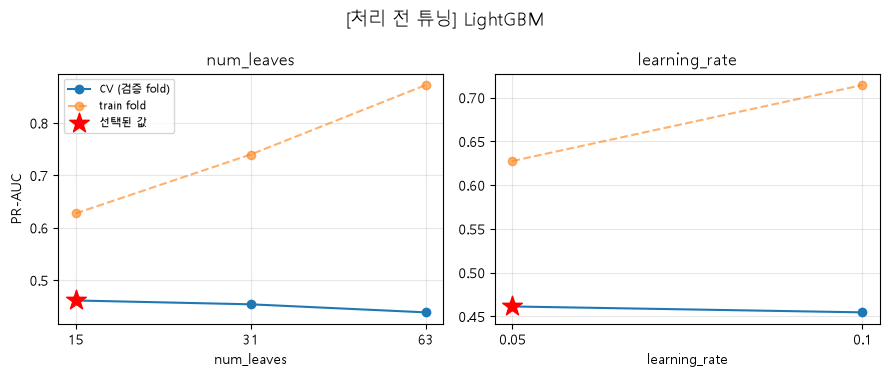

In [100]:
def plot_param_effect(search, title):
    """파라미터 값에 따라 CV PR-AUC가 어떻게 변하는지 파라미터마다 그래프 1개씩"""
    res = pd.DataFrame(search.cv_results_)
    grid = search.param_grid
    params = list(grid.keys())

    fig, axes = plt.subplots(1, len(params), figsize=(4.5 * len(params), 3.8), squeeze=False)

    for ax, p in zip(axes[0], params):
        labels = [str(v) for v in grid[p]]          # x축 라벨 (None도 'None'으로 표시)
        # 각 조합에서 이 파라미터가 어떤 값이었는지 (문자열로 통일해서 비교)
        col = pd.Series([str(d[p]) for d in search.cv_results_["params"]])

        # 값마다 '다른 파라미터를 가장 좋게 맞췄을 때'의 점수
        # → 이 값을 골랐을 때 도달할 수 있는 최고 성능
        test_best, train_at = [], []
        for v in labels:
            mask = (col == v).values
            best_idx = res.loc[mask, "mean_test_score"].idxmax()   # 그 값 중 CV가 가장 높은 조합
            test_best.append(res.loc[best_idx, "mean_test_score"])
            train_at.append(res.loc[best_idx, "mean_train_score"])  # 같은 조합의 train fold 점수

        x = np.arange(len(labels))
        ax.plot(x, test_best, marker="o", label="CV (검증 fold)")
        ax.plot(x, train_at, marker="o", ls="--", alpha=0.6, label="train fold")

        # 최종 선택된 값을 빨간 별로 표시
        bi = labels.index(str(search.best_params_[p]))
        ax.scatter(bi, test_best[bi], s=220, marker="*", color="red", zorder=5, label="선택된 값")

        ax.set_xticks(x)
        ax.set_xticklabels(labels)
        ax.set_xlabel(clean_name(p))
        ax.set_title(clean_name(p))
        ax.grid(alpha=0.3)

    axes[0][0].set_ylabel("PR-AUC")
    axes[0][0].legend(fontsize=8)
    fig.suptitle(title, fontsize=13)
    fig.tight_layout()
    plt.show()


for name, search in base_searches.items():
    plot_param_effect(search, f"[처리 전 튜닝] {name}")

- CV값이 가장 높은 지점에 빨간 색 별이 존재함(이 값이 선택된 이유를 말함)
- 실선이 평평한 것은 그 파라미터가 성능에 거의 영향을 미치지 않는 다는 것을 의미함
- 맨 끝에 있는 별은 탐색 범위 밖에 더 좋은 값이 있을 수 있다는 의미
- train fold와 cv 간격은 과적합 정도를 보여줌

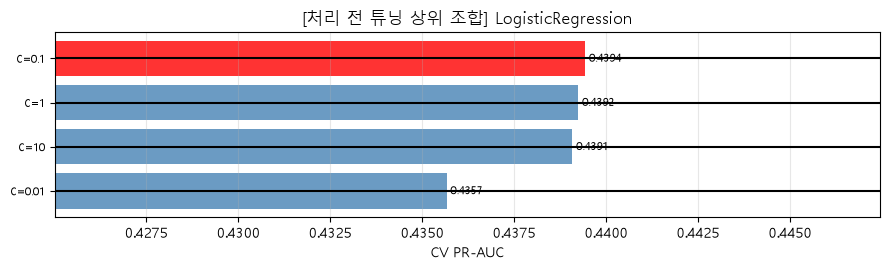

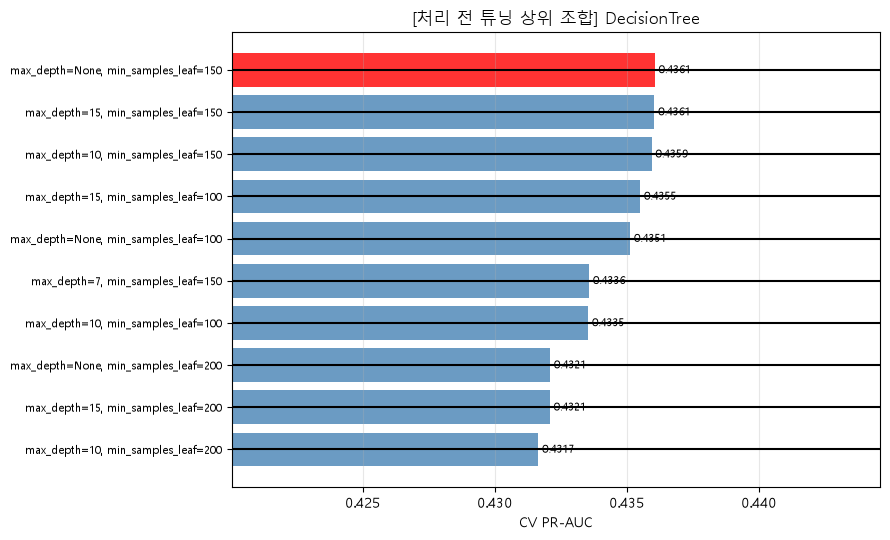

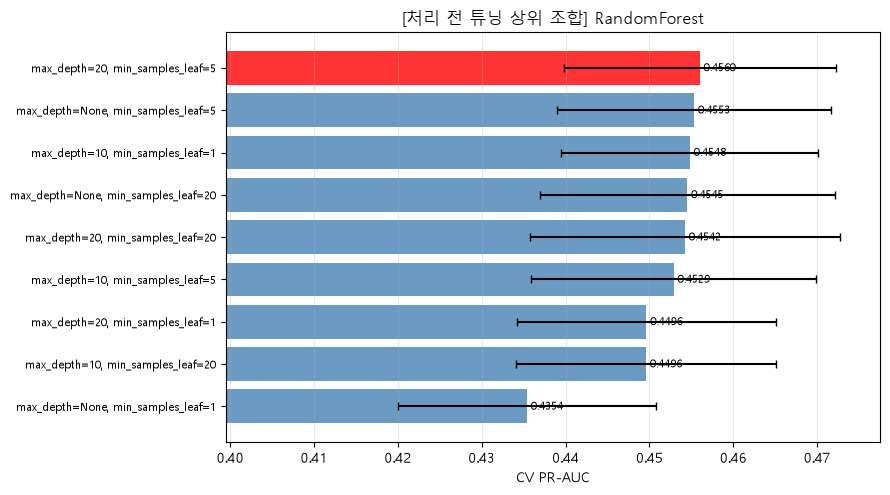

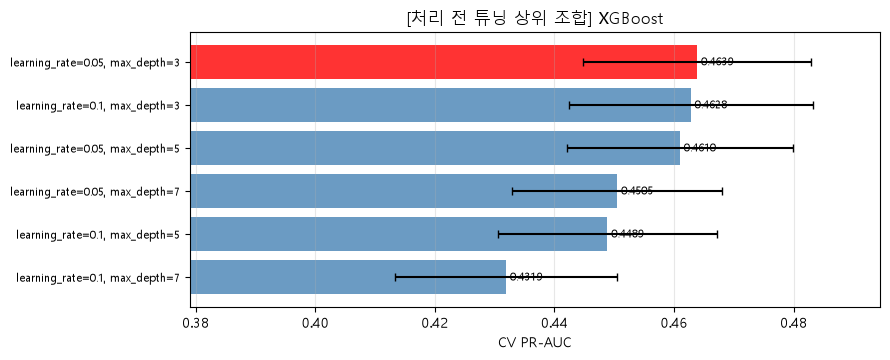

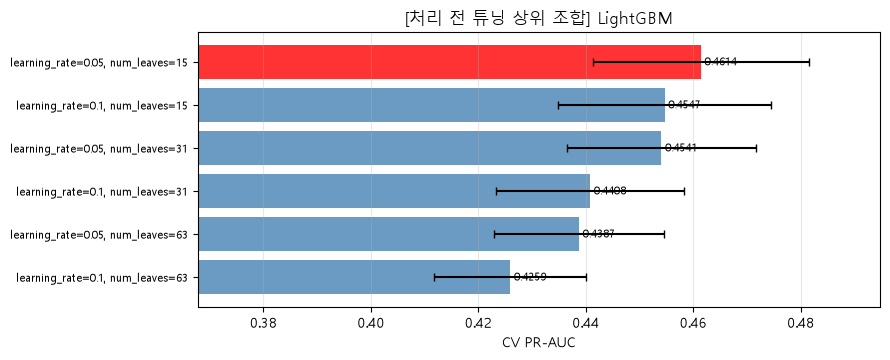

In [101]:
def plot_top_combos(search, title, top_n=10):
    """CV PR-AUC 상위 조합을 막대그래프로 (오차막대 = 5개 fold 간 표준편차)"""
    res = (pd.DataFrame(search.cv_results_)
           .sort_values("mean_test_score", ascending=False)
           .head(top_n))

    # y축 라벨: 'max_depth=3, learning_rate=0.05' 형식
    labels = [", ".join(f"{clean_name(k)}={v}" for k, v in params.items())
              for params in res["params"]]

    fig, ax = plt.subplots(figsize=(9, 0.45 * len(res) + 1))
    colors = ["red"] + ["steelblue"] * (len(res) - 1)    # 1등(선택된 조합)만 빨간색
    ax.barh(range(len(res)), res["mean_test_score"], xerr=res["std_test_score"],
            color=colors, alpha=0.8, capsize=3)
    ax.set_yticks(range(len(res)))
    ax.set_yticklabels(labels, fontsize=8)
    ax.invert_yaxis()                                     # 1등이 맨 위로

    # 막대 끝에 점수 표시
    for i, v in enumerate(res["mean_test_score"]):
        ax.text(v, i, f" {v:.4f}", va="center", fontsize=8)

    # 점수 차이가 잘 보이도록 x축 범위를 상위 조합 근처로 좁힘
    lo, hi = res["mean_test_score"].min(), res["mean_test_score"].max()
    ax.set_xlim(lo - (hi - lo) * 1.5 - 0.005, hi + (hi - lo) * 0.8 + 0.005)
    ax.set_xlabel("CV PR-AUC")
    ax.set_title(title)
    ax.grid(axis="x", alpha=0.3)
    fig.tight_layout()
    plt.show()


for name, search in base_searches.items():
    plot_top_combos(search, f"[처리 전 튜닝 상위 조합] {name}")

- 막대 끝의 선은 5개 fold간 점수의 흔들림을 말함
- 1등과 2~3등 차이가 흔들림보다 작으면 사실상 비슷한 성능이라는 의미

### 평가 함수

In [102]:
def evaluate(name, model, X_eval, y_eval, show_detail=True, fit_params=None):
    # fit_params: fit할 때 추가로 넘길 인자
    # - None이면 자동 설정: CatBoost 단독 모델이면 cat_features 전달, 나머지는 없음
    # - 샘플링 Pipeline 안의 CatBoost는 'clf__cat_features'처럼 단계 이름을 붙여야 해서
    #   ⑬ build_model에서 만든 값을 직접 넘겨받음
    if fit_params is None:
        fit_params = {"cat_features": cat_cols} if isinstance(model, CatBoostClassifier) else {}

    # 학습은 항상 train 데이터로만 진행 + 학습 시간 측정
    # (샘플링 Pipeline이면 이 fit 안에서 train에만 샘플링이 적용됨)
    start = time.time()
    model.fit(X_train, y_train, **fit_params)
    fit_time = time.time() - start

    # pred : 임계값 0.5 기준의 클래스 예측 (0 또는 1)
    # proba: yes(1)일 확률 → ROC-AUC, PR-AUC 계산에 사용
    # 예측 시에는 샘플링이 적용되지 않고 원본 validation 그대로 들어감
    pred = model.predict(X_eval)
    proba = model.predict_proba(X_eval)[:, 1]

    if show_detail:
        # 행 = 실제값, 열 = 예측값 / 실제 yes·예측 no 칸이 FN(놓친 가입 고객)
        cm = pd.DataFrame(confusion_matrix(y_eval, pred),
                          index=["실제 no", "실제 yes"],
                          columns=["예측 no", "예측 yes"])
        print(f"\n[{name}] 혼동행렬")
        display(cm)

    return {
        "model": name,
        "accuracy": accuracy_score(y_eval, pred),
        "precision": precision_score(y_eval, pred),   # yes로 예측한 것 중 실제 yes 비율
        "recall": recall_score(y_eval, pred),         # 실제 yes 중 모델이 찾아낸 비율
        "f1": f1_score(y_eval, pred),
        "roc_auc": roc_auc_score(y_eval, proba),
        "pr_auc": average_precision_score(y_eval, proba),
        # train PR-AUC: 원본 train 기준 (샘플링 전 데이터로 계산)
        "train_pr_auc": average_precision_score(y_train, model.predict_proba(X_train)[:, 1]),
        "fit_time_sec": fit_time,
    }

In [103]:
# 튜닝된 6개 모델을 validation 기준으로 평가
# (evaluate 안에서 모델별 혼동행렬이 display(cm)로 표 형태로 출력됨)
results = pd.DataFrame(
    [evaluate(n, m, X_val, y_val) for n, m in best_models.items()]
).set_index("model")

# ⑨에서 기록한 튜닝 소요 시간을 모델 이름 기준으로 붙임
results["tuning_time_sec"] = pd.DataFrame(tuning_log).set_index("model")["time_sec"]

# 1) 전체 결과 표: PR-AUC 높은 순으로 정렬, 소수점 4자리
print("\n[튜닝된 Baseline 성능 비교 (Validation 기준)]")
display(results.sort_values("pr_auc", ascending=False).round(4))

# 2) 지표별 최고 모델 표
# - 성능 지표는 '가장 큰 값'이 최고
# - 시간은 '가장 작은 값'이 최고 (가장 빠른 모델)
# - train_pr_auc는 과적합 확인용이라 제외
score_cols = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]
time_cols = ["fit_time_sec", "tuning_time_sec"]

best = pd.concat([
    pd.DataFrame({
        "best_model": results[score_cols].idxmax(),   # 지표별로 값이 가장 큰 모델
        "score": results[score_cols].max(),
    }),
    pd.DataFrame({
        "best_model": results[time_cols].idxmin(),    # 시간별로 값이 가장 작은 모델
        "score": results[time_cols].min(),
    }),
]).round(4)

print("\n[지표별 최고 모델]")
display(best)


[LogisticRegression] 혼동행렬


,예측 no,예측 yes
실제 no,7867,117
실제 yes,815,243



[DecisionTree] 혼동행렬


,예측 no,예측 yes
실제 no,7843,141
실제 yes,793,265



[RandomForest] 혼동행렬


...

,예측 no,예측 yes
실제 no,7841,143
실제 yes,779,279



[튜닝된 Baseline 성능 비교 (Validation 기준)]


,accuracy,precision,recall,f1,roc_auc,pr_auc,train_pr_auc,fit_time_sec,tuning_time_sec
model,,,,,,,,,
LightGBM,0.8980,0.6611,0.2637,0.3770,0.8170,0.4954,0.6100,0.1741,13.0
RandomForest,0.8966,0.6990,0.2042,0.3160,0.8088,0.4921,0.7216,1.6150,79.2
XGBoost,0.8969,0.6667,0.2382,0.3510,0.8126,0.4855,0.5144,0.1544,10.5
LogisticRegression,0.8969,0.6750,0.2297,0.3427,0.8017,0.4540,0.4444,0.1094,2.3
DecisionTree,0.8967,0.6527,0.2505,0.3620,0.7919,0.4437,0.4673,0.2361,38.0



[지표별 최고 모델]


,best_model,score
accuracy,LightGBM,0.8980
precision,RandomForest,0.6990
recall,LightGBM,0.2637
f1,LightGBM,0.3770
roc_auc,LightGBM,0.8170
pr_auc,LightGBM,0.4954
fit_time_sec,LogisticRegression,0.1094
tuning_time_sec,LogisticRegression,2.3000


### 클래스 분포 확인하고 불균형 처리 방법 정의하기
1. 불균형 데이터 처리
    - random undersampling(RUS), SMOTE-NC(수치형-범주형 섞여있음, YES 샘플과 그 이웃 사이 보간해서 새로운 YES 샘플 만들지만 범주형 값은 보간하지 않고 이웃 중 가장 많은 값을 사용)
    - class-weight='balance'
    - 데이터는 그대로 두고, yes 틀렸을 때 손실을 더 크게 주어 모델이 yes를 더 신경쓰게 만드는 방법

In [104]:
# train의 클래스별 개수 (XGBoost의 scale_pos_weight 계산에도 사용)
n_neg = (y_train == 0).sum()    # no 개수
n_pos = (y_train == 1).sum()    # yes 개수
print(f"train | no: {n_neg} / yes: {n_pos} / 비율 = 1 : {n_neg / n_pos:.2f}")

# 비율 이름 → sampling_strategy 값
# sampling_strategy = 처리 후 (yes 개수 / no 개수)
# - 1:1 → 1.0   (yes와 no가 같은 수)
# - 1:2 → 0.5   (no가 yes의 2배)
# - 1:3 → 0.333 (no가 yes의 3배)
ratios = {"1:1": 1.0, "1:2": 1 / 2, "1:3": 1 / 3}

# 비교할 방법 목록 (결과 표의 열 순서로도 사용)
methods = (["class_weight"]
           + [f"RUS {r}" for r in ratios]
           + [f"SMOTENC {r}" for r in ratios])
print("비교할 방법:", methods)


def make_sampler(method):
    """방법 이름(예: 'RUS 1:2', 'SMOTENC 1:3')에 맞는 샘플러 생성"""
    kind, ratio = method.split()             # 'RUS 1:2' → 'RUS', '1:2'
    strategy = ratios[ratio]

    if kind == "RUS":
        # no(다수 클래스)를 무작위로 줄여 목표 비율을 맞춤
        return RandomUnderSampler(sampling_strategy=strategy,
                                  random_state=RANDOM_STATE)
    if kind == "SMOTENC":
        # yes(소수 클래스)를 이웃 샘플 사이 보간으로 새로 만들어 목표 비율을 맞춤
        # categorical_features: 범주형 컬럼은 보간하지 않고 이웃들 중 가장 많은 값을 사용
        # → 'admin 30% + technician 70%' 같은 존재할 수 없는 값이 생기지 않음
        return SMOTENC(categorical_features=cat_cols,
                       sampling_strategy=strategy,
                       random_state=RANDOM_STATE)
    raise ValueError(f"알 수 없는 방법: {method}")

train | no: 23953 / yes: 3173 / 비율 = 1 : 7.55
비교할 방법: ['class_weight', 'RUS 1:1', 'RUS 1:2', 'RUS 1:3', 'SMOTENC 1:1', 'SMOTENC 1:2', 'SMOTENC 1:3']


### 모델 + 불균형 처리 조합 생성 함수

In [105]:
def build_model(name, method):
    """튜닝된 모델(best_models)에 불균형 처리 방법을 적용한 새 모델과 fit 인자를 반환"""
    # clone: 튜닝으로 찾은 하이퍼파라미터는 그대로 복사하고, 학습된 상태는 비운 새 모델 생성
    # (원본 best_models는 건드리지 않음)
    base = clone(best_models[name])
    is_catboost = isinstance(base, CatBoostClassifier)

    # ── 1) class_weight: 데이터는 그대로, yes를 틀렸을 때 손실을 더 크게 ──
    if method == "class_weight":
        # Pipeline이면 모델 단계(clf)를 꺼내고, CatBoost는 그 자체가 모델
        clf = base if is_catboost else base.named_steps["clf"]

        # 모델마다 옵션 이름이 다름 (효과는 모두 'yes에 no 대비 약 7.5배 가중치')
        if name == "XGBoost":
            clf.set_params(scale_pos_weight=n_neg / n_pos)      # no 개수 / yes 개수
        elif name == "CatBoost":
            clf.set_params(auto_class_weights="Balanced")
        else:   # LogisticRegression, DecisionTree, RandomForest, LightGBM
            clf.set_params(class_weight="balanced")

        fit_params = {"cat_features": cat_cols} if is_catboost else {}
        return base, fit_params

    # ── 2) RUS / SMOTE-NC: Pipeline 맨 앞에 샘플링 단계 추가 ──
    # 순서: 샘플링 → 전처리(원핫 등) → 모델
    # SMOTE-NC는 범주형이 문자열 상태일 때 적용해야 하므로 반드시 전처리보다 앞에 둠
    steps = [("clf", base)] if is_catboost else list(base.steps)
    model = ImbPipeline([("sampler", make_sampler(method))] + steps)

    # Pipeline 안의 CatBoost에 인자를 넘길 때는 '단계이름__인자명' 형식
    fit_params = {"clf__cat_features": cat_cols} if is_catboost else {}
    return model, fit_params

In [106]:
def build_model(name, method):
    """튜닝된 모델(best_models)에 불균형 처리 방법을 적용한 새 모델과 fit 인자를 반환"""
    # clone: 튜닝으로 찾은 하이퍼파라미터는 그대로 복사하고, 학습된 상태는 비운 새 모델 생성
    # (원본 best_models는 건드리지 않음)
    base = clone(best_models[name])
    is_catboost = isinstance(base, CatBoostClassifier)

    # ── 1) class_weight: 데이터는 그대로, yes를 틀렸을 때 손실을 더 크게 ──
    if method == "class_weight":
        # Pipeline이면 모델 단계(clf)를 꺼내고, CatBoost는 그 자체가 모델
        clf = base if is_catboost else base.named_steps["clf"]

        # 모델마다 옵션 이름이 다름 (효과는 모두 'yes에 no 대비 약 7.5배 가중치')
        if name == "XGBoost":
            clf.set_params(scale_pos_weight=n_neg / n_pos)      # no 개수 / yes 개수
        elif name == "CatBoost":
            clf.set_params(auto_class_weights="Balanced")
        else:   # LogisticRegression, DecisionTree, RandomForest, LightGBM
            clf.set_params(class_weight="balanced")

        fit_params = {"cat_features": cat_cols} if is_catboost else {}
        return base, fit_params

    # ── 2) RUS / SMOTE-NC: Pipeline 맨 앞에 샘플링 단계 추가 ──
    # 순서: 샘플링 → 전처리(원핫 등) → 모델
    # SMOTE-NC는 범주형이 문자열 상태일 때 적용해야 하므로 반드시 전처리보다 앞에 둠
    steps = [("clf", base)] if is_catboost else list(base.steps)
    model = ImbPipeline([("sampler", make_sampler(method))] + steps)

    # Pipeline 안의 CatBoost에 인자를 넘길 때는 '단계이름__인자명' 형식
    fit_params = {"clf__cat_features": cat_cols} if is_catboost else {}
    return model, fit_params

In [107]:
imb_results = []

for method in methods:
    for name in best_models:
        model, fit_params = build_model(name, method)

        # 42개 조합의 혼동행렬은 너무 많으므로 show_detail=False
        res = evaluate(name, model, X_val, y_val,
                       show_detail=False, fit_params=fit_params)
        res["method"] = method
        imb_results.append(res)

        print(f"{method:13s} | {name:20s} | PR-AUC: {res['pr_auc']:.4f} "
              f"| recall: {res['recall']:.4f} | {res['fit_time_sec']:.1f}초")

imb_df = pd.DataFrame(imb_results)

# ⑪의 튜닝된 baseline 결과를 '처리 전' 방법으로 붙여서 함께 비교
# (tuning_time_sec은 불균형 처리 결과에는 없으므로 제외)
baseline_df = (results.drop(columns="tuning_time_sec", errors="ignore")
               .reset_index()
               .assign(method="처리 전"))

all_results = pd.concat([baseline_df, imb_df], ignore_index=True)

class_weight  | LogisticRegression   | PR-AUC: 0.4478 | recall: 0.6654 | 0.1초
class_weight  | DecisionTree         | PR-AUC: 0.4438 | recall: 0.6560 | 0.2초
class_weight  | RandomForest         | PR-AUC: 0.4831 | recall: 0.6210 | 1.5초
class_weight  | XGBoost              | PR-AUC: 0.4852 | recall: 0.6465 | 0.2초
class_weight  | LightGBM             | PR-AUC: 0.4924 | recall: 0.6399 | 0.2초
RUS 1:1       | LogisticRegression   | PR-AUC: 0.4479 | recall: 0.6796 | 0.0초
RUS 1:1       | DecisionTree         | PR-AUC: 0.4342 | recall: 0.6285 | 0.0초
RUS 1:1       | RandomForest         | PR-AUC: 0.4684 | recall: 0.6531 | 0.4초
RUS 1:1       | XGBoost              | PR-AUC: 0.4684 | recall: 0.6541 | 0.1초
RUS 1:1       | LightGBM             | PR-AUC: 0.4713 | recall: 0.6673 | 0.1초
RUS 1:2       | LogisticRegression   | PR-AUC: 0.4472 | recall: 0.5359 | 0.1초
RUS 1:2       | DecisionTree         | PR-AUC: 0.4362 | recall: 0.5510 | 0.1초
RUS 1:2       | RandomForest         | PR-AUC: 0.4787 | recall: 

In [108]:
# 열 순서: baseline을 맨 앞에 두고 나머지 방법 순서대로
method_order = ["처리 전"] + methods

# 1) 지표별 '모델 × 방법' 표
# 행 = 모델, 열 = 불균형 처리 방법 → 같은 모델에서 방법별 변화를 한눈에 비교
for metric in ["pr_auc", "recall", "precision", "f1", "fit_time_sec"]:
    table = (all_results
             .pivot(index="model", columns="method", values=metric)
             [method_order]                         # 열 순서 정렬
             .round(4))
    print(f"\n[{metric} | 모델 × 불균형 처리 방법 (Validation 기준)]")
    display(table)

# 2) 전체 조합 상위 10개 (PR-AUC 기준)
print("\n[전체 조합 상위 10개 (PR-AUC 기준)]")
display(all_results
        .sort_values("pr_auc", ascending=False)
        .head(10)
        .set_index(["model", "method"])
        .round(4))

# 3) 지표별 최고 조합 (모델 + 방법)
score_cols = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]
best_rows = []
for col in score_cols:
    row = all_results.loc[all_results[col].idxmax()]     # 그 지표가 가장 높은 행
    best_rows.append({"metric": col, "model": row["model"],
                      "method": row["method"], "score": row[col]})
# 학습 시간은 가장 짧은 조합
row = all_results.loc[all_results["fit_time_sec"].idxmin()]
best_rows.append({"metric": "fit_time_sec", "model": row["model"],
                  "method": row["method"], "score": row["fit_time_sec"]})

print("\n[지표별 최고 조합]")
display(pd.DataFrame(best_rows).set_index("metric").round(4))

# 4) 모델별로 PR-AUC가 가장 좋았던 방법
best_per_model = all_results.loc[all_results.groupby("model")["pr_auc"].idxmax(),
                                 ["model", "method", "pr_auc", "recall", "f1"]]
print("\n[모델별 최고 방법 (PR-AUC 기준)]")
display(best_per_model.set_index("model").round(4))


[pr_auc | 모델 × 불균형 처리 방법 (Validation 기준)]


method,처리 전,class_weight,RUS 1:1,RUS 1:2,RUS 1:3,SMOTENC 1:1,SMOTENC 1:2,SMOTENC 1:3
model,,,,,,,,
DecisionTree,0.4437,0.4438,0.4342,0.4362,0.4500,0.4038,0.4300,0.4444
LightGBM,0.4954,0.4924,0.4713,0.4724,0.4835,0.4572,0.4848,0.4905
LogisticRegression,0.4540,0.4478,0.4479,0.4472,0.4491,0.4037,0.4199,0.4305
RandomForest,0.4921,0.4831,0.4684,0.4787,0.4827,0.4456,0.4674,0.4805
XGBoost,0.4855,0.4852,0.4684,0.4720,0.4819,0.4442,0.4678,0.4763



[recall | 모델 × 불균형 처리 방법 (Validation 기준)]


method,처리 전,class_weight,RUS 1:1,RUS 1:2,RUS 1:3,SMOTENC 1:1,SMOTENC 1:2,SMOTENC 1:3
model,,,,,,,,
DecisionTree,0.2505,0.6560,0.6285,0.5510,0.5510,0.5841,0.4915,0.4480
LightGBM,0.2637,0.6399,0.6673,0.6002,0.5624,0.5217,0.4707,0.4301
LogisticRegression,0.2297,0.6654,0.6796,0.5359,0.4556,0.6153,0.4820,0.4168
RandomForest,0.2042,0.6210,0.6531,0.5926,0.5491,0.5397,0.4754,0.4367
XGBoost,0.2382,0.6465,0.6541,0.5870,0.5406,0.5255,0.4660,0.4112



[precision | 모델 × 불균형 처리 방법 (Validation 기준)]


...

accuracy  precision  recall      f1  roc_auc  \
model        method                                                       
LightGBM     처리 전            0.8980     0.6611  0.2637  0.3770   0.8170   
             class_weight    0.8478     0.4049  0.6399  0.4960   0.8168   
RandomForest 처리 전            0.8966     0.6990  0.2042  0.3160   0.8088   
LightGBM     SMOTENC 1:3     0.8952     0.5688  0.4301  0.4898   0.8115   
XGBoost      처리 전            0.8969     0.6667  0.2382  0.3510   0.8126   
             class_weight    0.8440     0.3974  0.6465  0.4923   0.8175   
LightGBM     SMOTENC 1:2     0.8931     0.5503  0.4707  0.5074   0.8061   
             RUS 1:3         0.8822     0.4971  0.5624  0.5277   0.8157   
RandomForest class_weight    0.8578     0.4261  0.6210  0.5054   0.8112   
             RUS 1:3         0.8806     0.4907  0.5491  0.5183   0.8131   

                           pr_auc  train_pr_auc  fit_time_sec  
model        method                                            
LightGBM     처리 전          0.4954        0.6100        0.1741  
             class_weight  0.4924        0.5700        0.1899  
RandomForest 처리 전          0.4921        0.7216        1.6150  
LightGBM     SMOTENC 1:3   0.4905        0.5416        1.2028  
XGBoost      처리 전          0.4855        0.5144        0.1544  
             class_weight  0.4852        0.5031        0.1511  
LightGBM     SMOTENC 1:2   0.4848        0.5180        1.2690  
             RUS 1:3       0.4835        0.5640        0.1587  
RandomForest class_weight  0.4831        0.7418        1.4755  
             RUS 1:3       0.4827        0.6359        0.7036


[지표별 최고 조합]


,model,method,score
metric,,,
accuracy,LightGBM,처리 전,0.8980
precision,RandomForest,처리 전,0.6990
recall,LogisticRegression,RUS 1:1,0.6796
f1,LightGBM,RUS 1:3,0.5277
roc_auc,XGBoost,class_weight,0.8175
pr_auc,LightGBM,처리 전,0.4954
fit_time_sec,DecisionTree,RUS 1:1,0.0314



[모델별 최고 방법 (PR-AUC 기준)]


,method,pr_auc,recall,f1
model,,,,
DecisionTree,RUS 1:3,0.4500,0.5510,0.5004
LightGBM,처리 전,0.4954,0.2637,0.3770
LogisticRegression,처리 전,0.4540,0.2297,0.3427
RandomForest,처리 전,0.4921,0.2042,0.3160
XGBoost,처리 전,0.4855,0.2382,0.3510


In [109]:
summary = all_results.copy()

# ── 1) TP, FP 계산 (재학습 없이 recall, precision으로 역산) ──
# recall    = TP / 실제 yes 수   →  TP = recall × 실제 yes 수
# precision = TP / (TP + FP)     →  FP = TP / precision − TP
n_pos_val = (y_val == 1).sum()                       # validation의 실제 yes 수
summary["TP"] = (summary["recall"] * n_pos_val).round().astype(int)
summary["FP"] = np.where(
    summary["precision"] > 0,                        # precision이 0이면 나눗셈 불가 → 0 처리
    (summary["TP"] / summary["precision"] - summary["TP"]).round(),
    0,
).astype(int)

# ── 2) 표에 표시할 이름 정리 ──
# 이미지 형식에 맞춰 '처리 전' → '처리 없음', 'SMOTENC' → 'SMOTE'로 표시
summary["method_label"] = (summary["method"]
                           .replace({"처리 전": "처리 없음"})
                           .str.replace("SMOTENC", "SMOTE"))
# '모델 | 방법' 한 줄 라벨 (예: 'LightGBM | RUS 1:3')
summary["모델"] = summary["model"] + " | " + summary["method_label"]

# ── 3) 평균 순위 계산 ──
# 각 지표에서 값이 클수록 1위 (ascending=False)
# 네 지표의 순위를 평균 → 값이 작을수록 여러 지표에서 고르게 좋은 조합
rank_cols = ["accuracy", "precision", "recall", "f1"]
summary["평균 순위"] = summary[rank_cols].rank(ascending=False).mean(axis=1)

# ── 4) 표 형태로 정리 ──
summary_table = (
    summary
    .rename(columns={"accuracy": "Accuracy", "precision": "Precision",
                     "recall": "Recall", "f1": "F1", "pr_auc": "PR-AUC"})
    .set_index("모델")
    [["Accuracy", "Precision", "Recall", "F1", "평균 순위", "PR-AUC", "TP", "FP"]]
    .sort_values(["평균 순위", "PR-AUC"], ascending=[True, False])  # 순위 같으면 PR-AUC 높은 순
    .round(4)
)

# 상위 10개만 표시 (전체를 보려면 .head(10)을 지우면 됨)
print(f"[불균형 처리 방법별 성능 비교 (Validation 기준, 실제 yes = {n_pos_val}명)]")
display(summary_table.head(10))

[불균형 처리 방법별 성능 비교 (Validation 기준, 실제 yes = 1058명)]


,Accuracy,Precision,Recall,F1,평균 순위,PR-AUC,TP,FP
모델,,,,,,,,
LightGBM | RUS 1:3,0.8822,0.4971,0.5624,0.5277,11.25,0.4835,595,602
LightGBM | SMOTE 1:2,0.8931,0.5503,0.4707,0.5074,13.00,0.4848,498,407
LightGBM | RUS 1:2,0.8724,0.4649,0.6002,0.5239,13.75,0.4724,635,731
XGBoost | RUS 1:2,0.8736,0.4680,0.5870,0.5208,13.75,0.4720,621,706
RandomForest | RUS 1:3,0.8806,0.4907,0.5491,0.5183,14.50,0.4827,581,603
XGBoost | RUS 1:3,0.8812,0.4931,0.5406,0.5158,14.50,0.4819,572,588
XGBoost | SMOTE 1:2,0.8892,0.5301,0.4660,0.4960,15.00,0.4678,493,437
RandomForest | RUS 1:2,0.8717,0.4624,0.5926,0.5195,15.25,0.4787,627,729
RandomForest | SMOTE 1:3,0.8947,0.5648,0.4367,0.4925,15.50,0.4805,462,356


- 문제점 확인: year 데이터가 시간 순서를 학습해서 이후 데이터 셋을 예측하지 못하게 되는 문제가 발생할 수 있음 (ex. 이 데이터셋에는 2008년보다 2010년이 가입률이 매우 높음 -> 모델이 2010년이면 가입 확률이 높을 것이다라는 것을 배우는데 미래 데이터셋에서는 이 정보를 활용할 수 없음 )
- 이를 확인하기 위해서 

[연도별 건수와 가입률]


,건수,가입률
year,,
2008,27729,0.051
2009,14862,0.171
2010,2620,0.516


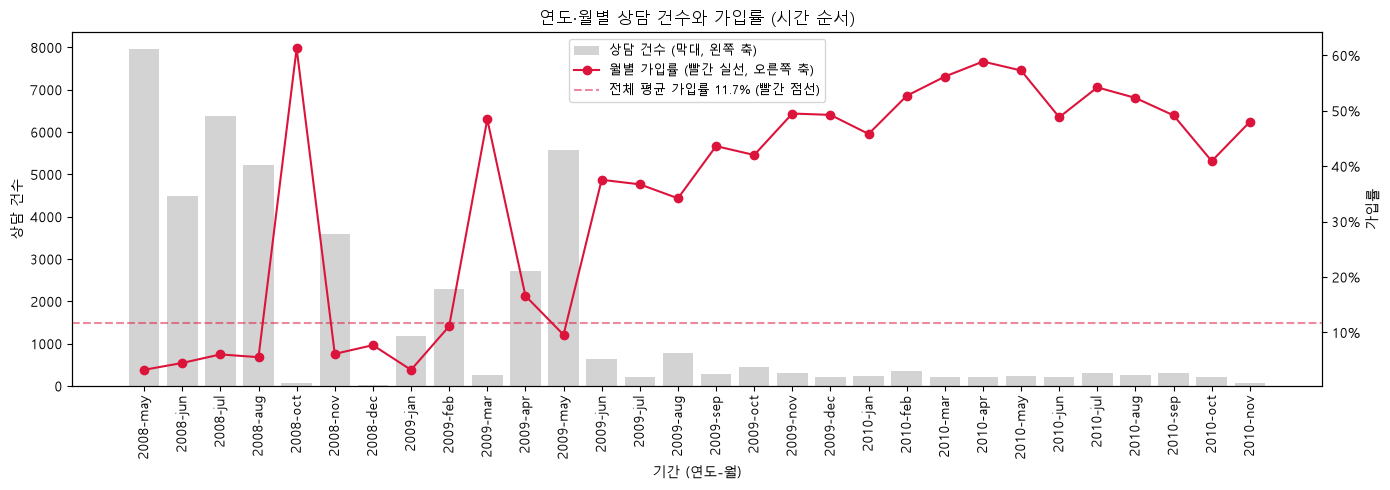

In [110]:
# 데이터가 원래 순서(시간순)대로 있는 df 사용
# sort=False: 데이터에 나온 순서(2008-05 → 2010-11)를 그대로 유지
period = (df.groupby(["year", "month"], sort=False)["y"]
          .agg(건수="count", 가입률="mean")
          .reset_index())
period["기간"] = period["year"].astype(str) + "-" + period["month"]

# 1) 연도별 요약
print("[연도별 건수와 가입률]")
display(df.groupby("year")["y"].agg(건수="count", 가입률="mean").round(3))

# 2) 월별 추이 그래프
fig, ax1 = plt.subplots(figsize=(14, 5))

# 막대: 그 달에 상담한 고객 수 (왼쪽 y축)
ax1.bar(period["기간"], period["건수"], color="lightgray", label="상담 건수 (막대, 왼쪽 축)")
ax1.set_ylabel("상담 건수")
ax1.set_xlabel("기간 (연도-월)")
ax1.tick_params(axis="x", rotation=90)

# 선: 그 달에 상담한 고객 중 정기예금에 가입한 비율 (오른쪽 y축)
ax2 = ax1.twinx()                                   # 같은 x축을 공유하는 두 번째 y축
ax2.plot(period["기간"], period["가입률"], color="crimson", marker="o",
         label="월별 가입률 (빨간 실선, 오른쪽 축)")
# 점선: 전체 데이터의 평균 가입률 → 이보다 위면 평균보다 가입이 잘 된 달
avg_rate = df["y"].mean()
ax2.axhline(avg_rate, color="crimson", ls="--", alpha=0.5,
            label=f"전체 평균 가입률 {avg_rate:.1%} (빨간 점선)")
ax2.set_ylabel("가입률")
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))   # 0.5 → 50%

# 범례 합치기
# 막대(ax1)와 선(ax2)이 서로 다른 축에 그려져 있어서, 각 축의 범례 항목을 모아 하나로 표시
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper center", fontsize=9)

ax1.set_title("연도·월별 상담 건수와 가입률 (시간 순서)")
fig.tight_layout()
plt.show()

#### 이전 year데이터 있을 때 시간순 모델 확인하기 위해 사용했던 코드

In [114]:

# def build_pipe(name, cats):
#     """튜닝된 모델의 하이퍼파라미터는 그대로 두고, 사용할 범주형 변수만 바꾼 Pipeline 생성"""
#     clf = clone(best_models[name].named_steps["clf"])     # 튜닝된 하이퍼파라미터 복사
#     # LR만 스케일링, 나머지(트리 계열)는 수치형 그대로
#     num_step = StandardScaler() if name == "LogisticRegression" else "passthrough"
#     prep = ColumnTransformer([
#         ("num", num_step, num_cols),
#         ("cat", OneHotEncoder(handle_unknown="ignore"), cats),   # 목록에 없는 컬럼은 자동으로 제외됨
#     ])
#     return Pipeline([("prep", prep), ("clf", clf)])


# # 분할 방식 2가지 (학습 60% / 평가 20%로 크기를 맞춤)
# n = len(X)
# cut_train, cut_eval = int(n * 0.6), int(n * 0.8)
# split_sets = {
#     # 지금까지 써온 방식: 시간과 무관하게 섞어서 나눔
#     "무작위 분할": (X_train, y_train, X_val, y_val),
#     # 실제 사용 상황과 같은 방식: 과거로 학습 → 그 이후 기간을 예측
#     # (X는 원본 순서 = 시간순이므로 앞부분이 과거)
#     "시간순 분할": (X.iloc[:cut_train], y.iloc[:cut_train],
#                 X.iloc[cut_train:cut_eval], y.iloc[cut_train:cut_eval]),
# }

# # year 포함 / 제외 변수 목록
# cat_sets = {
#     "year 포함": cat_cols,
#     "year 제외": [c for c in cat_cols if c != "year"],
# }

# year_rows = []
# for split_name, (Xa, ya, Xb, yb) in split_sets.items():
#     for cat_name, cats in cat_sets.items():
#         for name in best_models:
#             model = build_pipe(name, cats).fit(Xa, ya)
#             proba = model.predict_proba(Xb)[:, 1]     # yes 확률 → PR-AUC, ROC-AUC
#             pred = model.predict(Xb)                   # 임계값 0.5 기준 예측 → F1, Recall, Precision
#             year_rows.append({
#                 "model": name,
#                 "분할": split_name,
#                 "변수": cat_name,
#                 "PR-AUC": average_precision_score(yb, proba),
#                 "ROC-AUC": roc_auc_score(yb, proba),
#                 # zero_division=0: yes로 예측한 건이 하나도 없으면 경고 대신 0으로 처리
#                 # (시간순 분할에서는 yes 예측이 거의 없을 수 있음)
#                 "F1": f1_score(yb, pred, zero_division=0),
#                 "Recall": recall_score(yb, pred, zero_division=0),
#                 "Precision": precision_score(yb, pred, zero_division=0),
#                 # PR-AUC는 평가 데이터의 가입률(무작위로 찍었을 때의 점수)이 기준선이므로 함께 표시
#                 "평가 가입률": yb.mean(),
#             })
#         print(f"{split_name} | {cat_name} 완료")

# # 학습·평가 기간에 어떤 연도가 들어갔는지 확인
# print("\n[시간순 분할의 기간 구성]")
# print("학습:", X.iloc[:cut_train]["year"].value_counts().to_dict())
# print("평가:", X.iloc[cut_train:cut_eval]["year"].value_counts().to_dict())

# # 한 표로 정리: 모델 → 분할 → 변수 순으로 묶어서 같은 모델의 4가지 설정을 위아래로 비교
# year_table = (pd.DataFrame(year_rows)
#               .set_index(["model", "분할", "변수"])
#               .sort_index(level=["model", "분할", "변수"],
#                           ascending=[True, True, True])   # 무작위 → 시간순, year 포함 → 제외 순
#               [["PR-AUC", "ROC-AUC", "F1", "Recall", "Precision", "평가 가입률"]]
#               .round(4))

# print("\n[분할 방식 × year 포함 여부 비교 (모든 모델, 임계값 0.5 기준)]")
# display(year_table)

In [112]:
# 비교할 피처 구성 3가지
# - 기준이 되는 변수: 지금 피처 정의에서 month_contacts와 year를 뺀 나머지
base_num = [c for c in num_cols if c != "month_contacts"]
base_cat = [c for c in cat_cols if c != "year"]

feature_sets = {
    "year 포함 (기존)":       (base_num, base_cat + ["year"]),
    "year 제외":             (base_num, base_cat),
    "month_contacts로 대체":  (base_num + ["month_contacts"], base_cat),
}


def build_pipe(name, nums, cats):
    """튜닝된 모델의 하이퍼파라미터는 그대로 두고, 사용할 변수만 바꾼 Pipeline 생성"""
    clf = clone(best_models[name].named_steps["clf"])     # 튜닝된 하이퍼파라미터 복사
    # LR만 스케일링, 나머지(트리 계열)는 수치형 그대로
    num_step = StandardScaler() if name == "LogisticRegression" else "passthrough"
    prep = ColumnTransformer([
        ("num", num_step, nums),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cats),   # 목록에 없는 컬럼은 자동으로 제외됨
    ])
    return Pipeline([("prep", prep), ("clf", clf)])


# X에는 이제 year가 없으므로, 비교에 필요한 모든 컬럼을 원본 df에서 가져옴
# (year는 숫자형이어도 OneHotEncoder가 범주로 처리하므로 그대로 사용 가능)
all_cols = base_num + ["month_contacts"] + base_cat + ["year"]
X_all = df[all_cols]

# 분할 방식 2가지 (학습 60% / 평가 20%로 크기를 맞춤)
n = len(df)
cut_train, cut_eval = int(n * 0.6), int(n * 0.8)
split_sets = {
    # 지금까지 써온 방식: X_train, X_val과 '같은 행'을 사용 (index로 맞춤)
    "무작위 분할": (X_all.loc[X_train.index], y_train,
                X_all.loc[X_val.index], y_val),
    # 실제 사용 상황과 같은 방식: 과거로 학습 → 그 이후 기간을 예측
    # (df는 원본 순서 = 시간순이므로 앞부분이 과거)
    "시간순 분할": (X_all.iloc[:cut_train], y.iloc[:cut_train],
                X_all.iloc[cut_train:cut_eval], y.iloc[cut_train:cut_eval]),
}

feat_rows = []
for split_name, (Xa, ya, Xb, yb) in split_sets.items():
    for feat_name, (nums, cats) in feature_sets.items():
        for name in best_models:
            model = build_pipe(name, nums, cats).fit(Xa, ya)
            proba = model.predict_proba(Xb)[:, 1]     # yes 확률 → PR-AUC, ROC-AUC
            pred = model.predict(Xb)                   # 임계값 0.5 기준 예측 → F1, Recall, Precision
            feat_rows.append({
                "model": name,
                "분할": split_name,
                "피처 구성": feat_name,
                "PR-AUC": average_precision_score(yb, proba),
                "ROC-AUC": roc_auc_score(yb, proba),
                # zero_division=0: yes로 예측한 건이 하나도 없으면 경고 대신 0으로 처리
                "F1": f1_score(yb, pred, zero_division=0),
                "Recall": recall_score(yb, pred, zero_division=0),
                "Precision": precision_score(yb, pred, zero_division=0),
                # PR-AUC는 평가 데이터의 가입률(무작위로 찍었을 때의 점수)이 기준선이므로 함께 표시
                "평가 가입률": yb.mean(),
            })
        print(f"{split_name} | {feat_name} 완료")

# 시간순 분할의 학습·평가 기간에 어떤 연도가 들어갔는지 확인 (year는 df에서 확인)
print("\n[시간순 분할의 기간 구성]")
print("학습:", df["year"].iloc[:cut_train].value_counts().to_dict())
print("평가:", df["year"].iloc[cut_train:cut_eval].value_counts().to_dict())

# 한 표로 정리: 모델 → 분할 → 피처 구성 순서
feat_order = list(feature_sets.keys())
feat_table = (pd.DataFrame(feat_rows)
              .assign(**{"피처 구성": lambda d: pd.Categorical(d["피처 구성"],
                                                          categories=feat_order,
                                                          ordered=True)})   # 정의한 순서대로 정렬
              .sort_values(["model", "분할", "피처 구성"])
              .set_index(["model", "분할", "피처 구성"])
              [["PR-AUC", "ROC-AUC", "F1", "Recall", "Precision", "평가 가입률"]]
              .round(4))

print("\n[피처 구성 × 분할 방식 비교 (모든 모델, 임계값 0.5 기준)]")
display(feat_table)

무작위 분할 | year 포함 (기존) 완료
무작위 분할 | year 제외 완료
무작위 분할 | month_contacts로 대체 완료
시간순 분할 | year 포함 (기존) 완료
시간순 분할 | year 제외 완료
시간순 분할 | month_contacts로 대체 완료

[시간순 분할의 기간 구성]
학습: {2008: 27126}
평가: {2009: 8439, 2008: 603}

[피처 구성 × 분할 방식 비교 (모든 모델, 임계값 0.5 기준)]


PR-AUC  ROC-AUC      F1  Recall  \
model              분할     피처 구성                                                 
DecisionTree       무작위 분할 year 포함 (기존)        0.4558   0.7995  0.3880  0.2760   
                          year 제외             0.4199   0.7762  0.3051  0.1975   
                          month_contacts로 대체  0.4437   0.7919  0.3620  0.2505   
                   시간순 분할 year 포함 (기존)        0.1519   0.5701  0.0000  0.0000   
                          year 제외             0.1520   0.5702  0.0000  0.0000   
                          month_contacts로 대체  0.1425   0.5477  0.0000  0.0000   
LightGBM           무작위 분할 year 포함 (기존)        0.4959   0.8173  0.3955  0.2817   
                          year 제외             0.4693   0.8052  0.3701  0.2571   
                          month_contacts로 대체  0.4954   0.8170  0.3770  0.2637   
                   시간순 분할 year 포함 (기존)        0.1421   0.5725  0.0000  0.0000   
                          year 제외             0.1421   0.5725  0.0000  0.0000   
                          month_contacts로 대체  0.1150   0.5053  0.1102  0.1238   
LogisticRegression 무작위 분할 year 포함 (기존)        0.4524   0.8014  0.3250  0.2146   
                          year 제외             0.4193   0.7808  0.2853  0.1805   
                          month_contacts로 대체  0.4540   0.8017  0.3427  0.2297   
                   시간순 분할 year 포함 (기존)        0.1702   0.6309  0.0000  0.0000   
                          year 제외             0.1690   0.6219  0.0000  0.0000   
                          month_contacts로 대체  0.1771   0.6171  0.0218  0.0113   
RandomForest       무작위 분할 year 포함 (기존)        0.4852   0.8080  0.3415  0.2250   
                          year 제외             0.4604   0.7990  0.2926  0.1843   
                          month_contacts로 대체  0.4921   0.8088  0.3160  0.2042   
                   시간순 분할 year 포함 (기존)        0.1535   0.5676  0.0000  0.0000   
                          year 제외             0.1551   0.5739  0.0000  0.0000   
                          month_contacts로 대체  0.1311   0.5467  0.0000  0.0000   
XGBoost            무작위 분할 year 포함 (기존)        0.4960   0.8184  0.3913  0.2713   
                          year 제외             0.4672   0.8083  0.3333  0.2221   
                          month_contacts로 대체  0.4855   0.8126  0.3510  0.2382   
                   시간순 분할 year 포함 (기존)        0.1448   0.5789  0.0000  0.0000   
                          year 제외             0.1448   0.5789  0.0000  0.0000   
                          month_contacts로 대체  0.1431   0.5840  0.2390  0.6745   

                                              Precision  평가 가입률  
model              분할     피처 구성                                  
DecisionTree       무작위 분할 year 포함 (기존)           0.6532  0.1170  
                          year 제외                0.6699  0.1170  
                          month_contacts로 대체     0.6527  0.1170  
                   시간순 분할 year 포함 (기존)           0.0000  0.1179  
                          year 제외                0.0000  0.1179  
                          month_contacts로 대체     0.0000  0.1179  
LightGBM           무작위 분할 year 포함 (기존)           0.6637  0.1170  
                          year 제외                0.6602  0.1170  
                          month_contacts로 대체     0.6611  0.1170  
                   시간순 분할 year 포함 (기존)           0.0000  0.1179  
                          year 제외                0.0000  0.1179  
                          month_contacts로 대체     0.0992  0.1179  
LogisticRegression 무작위 분할 year 포함 (기존)           0.6696  0.1170  
                          year 제외                0.6797  0.1170  
                          month_contacts로 대체     0.6750  0.1170  
                   시간순 분할 year 포함 (기존)           0.0000  0.1179  
                          year 제외                0.0000  0.1179  
                          month_contacts로 대체     0.3529  0.1179  
RandomForest       무작위 분할 year 포함 (기존)           0.7083  0.1170  
                          year 제외                0.7091  0.1170  
 

#### 하이퍼파라미터 튜닝(최종 선정한 불균형 처리 모델에 맞춰)

In [115]:
# 몇 개 모델을 다시 튜닝할지
TOP_K = 3

# ⑯의 summary에서 평균 순위가 좋은 순으로 정렬한 뒤, 모델마다 가장 좋은 조합 하나씩만 선택
# - '처리 전'은 이미 ⑨에서 튜닝을 마쳤으므로 후보에서 제외
# - drop_duplicates("model"): 같은 모델이 여러 번 뽑히지 않도록 모델별 첫 번째(=최고) 조합만 남김
#   (그대로 상위 3개를 뽑으면 LightGBM만 비율을 바꿔 3번 들어가서 모델 간 비교가 안 됨)
# - 평균 순위가 같으면 PR-AUC가 높은 조합 우선
candidates = (summary[summary["method"] != "처리 전"]
              .sort_values(["평균 순위", "pr_auc"], ascending=[True, False])
              .drop_duplicates("model")
              .head(TOP_K)[["model", "method"]])

# 직접 고르고 싶으면 위 대신 아래처럼 지정
# candidates = pd.DataFrame([("LightGBM", "RUS 1:3"),
#                            ("LightGBM", "SMOTENC 1:2")], columns=["model", "method"])

print("[다시 튜닝할 조합]")
display(candidates.reset_index(drop=True))

[다시 튜닝할 조합]


,model,method
0,LightGBM,RUS 1:3
1,XGBoost,RUS 1:2
2,RandomForest,RUS 1:3


In [116]:
# 처리 전 튜닝(search_space)보다 넓은 범위
# - 처리 전에 최적값이 범위 끝(XGBoost depth 3, LightGBM leaves 15, lr 0.05)에 걸렸으므로 더 작은 값 추가
# - 파라미터 이름에 'clf__'는 붙이지 않음 → ⑲에서 모델 구조에 맞게 자동으로 붙임
tune_grids = {
    "LogisticRegression": {
        "C": [0.01, 0.03, 0.1, 0.3, 1],                  # 규제 강도의 역수
    },
    "DecisionTree": {
        "max_depth": [5, 7, 10, None],
        "min_samples_leaf": [20, 50, 100, 150, 200],     # 리프 최소 샘플 수 (과적합 방지 핵심)
    },
    "RandomForest": {
        "n_estimators": [300, 500],
        "max_depth": [10, 20, None],
        "min_samples_leaf": [1, 5, 10, 20],
        "max_features": ["sqrt", 0.3],                   # 분기마다 고려할 변수 비율 (작을수록 트리 간 다양성↑)
    },
    "XGBoost": {
        "max_depth": [2, 3, 4, 5],
        "learning_rate": [0.03, 0.05, 0.1],
        "n_estimators": [300, 500],                      # learning_rate가 작으면 트리가 더 많이 필요
        "subsample": [0.8, 1.0],                         # 트리마다 사용할 행 비율 (1 미만이면 과적합 완화)
    },
    "LightGBM": {
        "num_leaves": [7, 15, 31],
        "learning_rate": [0.03, 0.05, 0.1],
        "n_estimators": [300, 500],
        "min_child_samples": [20, 50],                   # 리프 최소 샘플 수
    },
    "CatBoost": {
        "depth": [4, 5, 6, 8],
        "learning_rate": [0.03, 0.05, 0.1],
        "l2_leaf_reg": [3, 10],                          # L2 규제 (클수록 과적합 완화)
    },
}

# SMOTE-NC의 이웃 수(k_neighbors)도 같이 튜닝할지
# - True로 하면 SMOTE-NC 조합의 탐색 시간이 3배가 됨
TUNE_K_NEIGHBORS = False


def param_prefix(model):
    """모델 구조에 맞는 파라미터 접두어 반환
    - Pipeline / ImbPipeline: 모델 단계 이름이 'clf'이므로 'clf__'
    - CatBoost 단독(class_weight 방법): 접두어 없음"""
    return "clf__" if hasattr(model, "named_steps") else ""

In [117]:
tuned_models = {}      # (모델, 방법) → 튜닝된 모델
tuned_log = []         # 튜닝 결과 기록
tuned_searches = {}    # (모델, 방법) → GridSearchCV 객체 (탐색 과정 전체, 시각화에 사용)

for _, row in candidates.iterrows():
    name, method = row["model"], row["method"]
    start = time.time()

    # build_model로 '샘플러 + 전처리 + 모델' 또는 'class_weight 적용 모델' 생성
    # (처리 전 튜닝에서 찾은 파라미터가 시작값으로 들어 있고, 아래 grid 값으로 덮어씌워짐)
    model, fit_params = build_model(name, method)

    # 모델 구조에 맞게 파라미터 이름에 접두어 붙이기 (예: max_depth → clf__max_depth)
    prefix = param_prefix(model)
    grid = {prefix + k: v for k, v in tune_grids[name].items()}

    # SMOTE-NC 이웃 수 튜닝 (샘플러 단계 이름이 'sampler'이므로 'sampler__')
    if TUNE_K_NEIGHBORS and method.startswith("SMOTENC"):
        grid["sampler__k_neighbors"] = [3, 5, 7]

    search = GridSearchCV(
        model,
        grid,
        # 여러 지표를 함께 기록하고, 최적 조합은 PR-AUC 기준으로 선택
        scoring={"pr_auc": "average_precision", "f1": "f1", "recall": "recall"},
        refit="pr_auc",
        cv=cv,                       # 처리 전 튜닝과 같은 5-fold → 공정한 비교
        n_jobs=1,
        return_train_score=True,     # train fold 점수도 기록 (과적합 확인용 그래프에 사용)
    )
    # 샘플링은 각 fold의 학습 부분에만 적용되고, 평가 fold는 원본 그대로 유지됨
    search.fit(X_train, y_train, **fit_params)

    tuned_models[(name, method)] = search.best_estimator_
    tuned_searches[(name, method)] = search
    best_i = search.best_index_
    tuned_log.append({
        "model": name,
        "method": method,
        "best_params": search.best_params_,
        "cv_pr_auc": round(search.best_score_, 4),
        "cv_f1": round(search.cv_results_["mean_test_f1"][best_i], 4),
        "cv_recall": round(search.cv_results_["mean_test_recall"][best_i], 4),
        "n_candidates": len(search.cv_results_["params"]),      # 탐색한 조합 수
        "time_sec": round(time.time() - start, 1),
    })
    print(f"{name:20s} | {method:12s} 완료 | CV PR-AUC: {search.best_score_:.4f} "
          f"| {time.time() - start:.0f}초")

print("\n[튜닝 결과]")
display(pd.DataFrame(tuned_log).set_index(["model", "method"]))

LightGBM             | RUS 1:3      완료 | CV PR-AUC: 0.4634 | 74초
XGBoost              | RUS 1:2      완료 | CV PR-AUC: 0.4611 | 85초
RandomForest         | RUS 1:3      완료 | CV PR-AUC: 0.4570 | 399초

[튜닝 결과]


,,best_params,cv_pr_auc,cv_f1,cv_recall,n_candidates,time_sec
model,method,,,,,,
LightGBM,RUS 1:3,"{'clf__learning_rate': 0.03, 'clf__min_child_s...",0.4634,0.4996,0.5118,36,74.4
XGBoost,RUS 1:2,"{'clf__learning_rate': 0.05, 'clf__max_depth':...",0.4611,0.5043,0.5613,48,85.1
RandomForest,RUS 1:3,"{'clf__max_depth': 10, 'clf__max_features': 0....",0.4570,0.5007,0.5279,48,399.5


In [118]:
# 튜닝된 모델을 validation으로 평가
after_rows = []
for (name, method), model in tuned_models.items():
    _, fit_params = build_model(name, method)          # CatBoost용 fit 인자만 다시 가져옴
    res = evaluate(name, model, X_val, y_val, show_detail=False, fit_params=fit_params)
    res.update({"method": method, "구분": "튜닝 후"})
    after_rows.append(res)
after_df = pd.DataFrame(after_rows)

# 같은 조합의 튜닝 전 결과(⑭, 처리 전 파라미터 고정)를 가져옴
tuned_before_df = (all_results
                   .merge(candidates, on=["model", "method"])  # 후보 조합만 남김
                   .assign(구분="튜닝 전"))

compare = pd.concat([tuned_before_df, after_df], ignore_index=True)

# TP, FP 역산 (⑯과 같은 방식)
compare["TP"] = (compare["recall"] * n_pos_val).round().astype(int)
compare["FP"] = np.where(compare["precision"] > 0,
                         (compare["TP"] / compare["precision"] - compare["TP"]).round(),
                         0).astype(int)

# '모델 | 방법 | 튜닝 전/후' 라벨
compare["모델"] = (compare["model"] + " | "
                   + compare["method"].str.replace("SMOTENC", "SMOTE")
                   + " | " + compare["구분"])

compare_table = (
    compare
    .rename(columns={"accuracy": "Accuracy", "precision": "Precision",
                     "recall": "Recall", "f1": "F1", "pr_auc": "PR-AUC",
                     "fit_time_sec": "학습 시간(초)"})
    .sort_values(["model", "method", "구분"], ascending=[True, True, False])  # 같은 조합끼리 전→후 순서
    .set_index("모델")
    [["Accuracy", "Precision", "Recall", "F1", "PR-AUC", "TP", "FP", "학습 시간(초)"]]
    .round(4)
)

print(f"[튜닝 전/후 비교 (Validation 기준, 실제 yes = {n_pos_val}명)]")
display(compare_table)

[튜닝 전/후 비교 (Validation 기준, 실제 yes = 1058명)]


,Accuracy,Precision,Recall,F1,PR-AUC,TP,FP,학습 시간(초)
모델,,,,,,,,
LightGBM | RUS 1:3 | 튜닝 후,0.8812,0.4934,0.5643,0.5265,0.4887,597,613,0.1717
LightGBM | RUS 1:3 | 튜닝 전,0.8822,0.4971,0.5624,0.5277,0.4835,595,602,0.1587
RandomForest | RUS 1:3 | 튜닝 후,0.8788,0.4843,0.5558,0.5176,0.4872,588,626,0.6820
RandomForest | RUS 1:3 | 튜닝 전,0.8806,0.4907,0.5491,0.5183,0.4827,581,603,0.7036
XGBoost | RUS 1:2 | 튜닝 후,0.8733,0.4670,0.5888,0.5209,0.4769,623,711,0.1206
XGBoost | RUS 1:2 | 튜닝 전,0.8736,0.4680,0.5870,0.5208,0.4720,621,706,0.1214


In [119]:
def clean_name(param):
    """'clf__max_depth' → 'max_depth', 'sampler__k_neighbors' → 'sampler: k_neighbors'"""
    return param.replace("clf__", "").replace("sampler__", "sampler: ")


rows = []
for (name, method), search in tuned_searches.items():
    for p, values in search.param_grid.items():
        rows.append({
            "모델": f"{name} | {method.replace('SMOTENC', 'SMOTE')}",
            "파라미터": clean_name(p),
            "탐색한 값": ", ".join(str(v) for v in values),
            # str(): None이 숫자와 섞이면 pandas가 NaN으로 바꿔 표시하므로 문자열로 고정
            "선택된 값": str(search.best_params_[p]),
            "조합 수": len(search.cv_results_["params"]),
            "최적 CV PR-AUC": round(search.best_score_, 4),
        })

print("[불균형 처리 후 재튜닝: 탐색한 값과 선택된 값]")
display(pd.DataFrame(rows).set_index(["모델", "파라미터"]))

[불균형 처리 후 재튜닝: 탐색한 값과 선택된 값]


탐색한 값 선택된 값  조합 수  \
모델                     파라미터                                             
LightGBM | RUS 1:3     num_leaves               7, 15, 31    15    36   
                       learning_rate      0.03, 0.05, 0.1  0.03    36   
                       n_estimators              300, 500   300    36   
                       min_child_samples           20, 50    50    36   
XGBoost | RUS 1:2      max_depth               2, 3, 4, 5     3    48   
                       learning_rate      0.03, 0.05, 0.1  0.05    48   
                       n_estimators              300, 500   300    48   
                       subsample                 0.8, 1.0   0.8    48   
RandomForest | RUS 1:3 n_estimators              300, 500   300    48   
                       max_depth             10, 20, None    10    48   
                       min_samples_leaf      1, 5, 10, 20     5    48   
                       max_features             sqrt, 0.3   0.3    48   

                                          최적 CV PR-AUC  
모델                     파라미터                             
LightGBM | RUS 1:3     num_leaves               0.4634  
                       learning_rate            0.4634  
                       n_estimators             0.4634  
                       min_child_samples        0.4634  
XGBoost | RUS 1:2      max_depth                0.4611  
                       learning_rate            0.4611  
                       n_estimators             0.4611  
                       subsample                0.4611  
RandomForest | RUS 1:3 n_estimators             0.4570  
                       max_depth                0.4570  
                       min_samples_leaf         0.4570  
                       max_features             0.4570

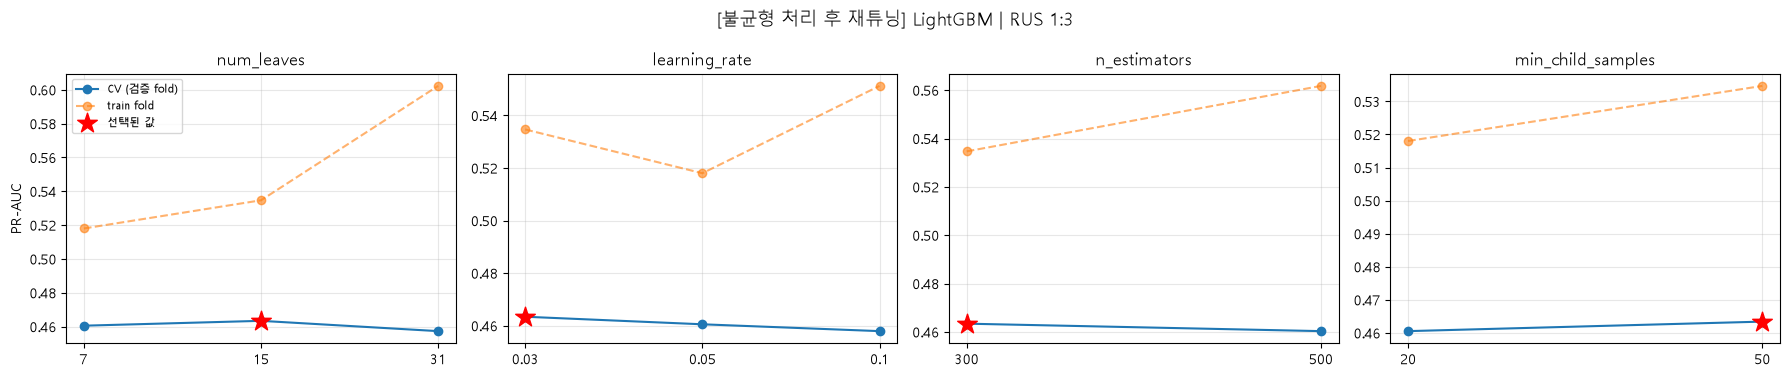

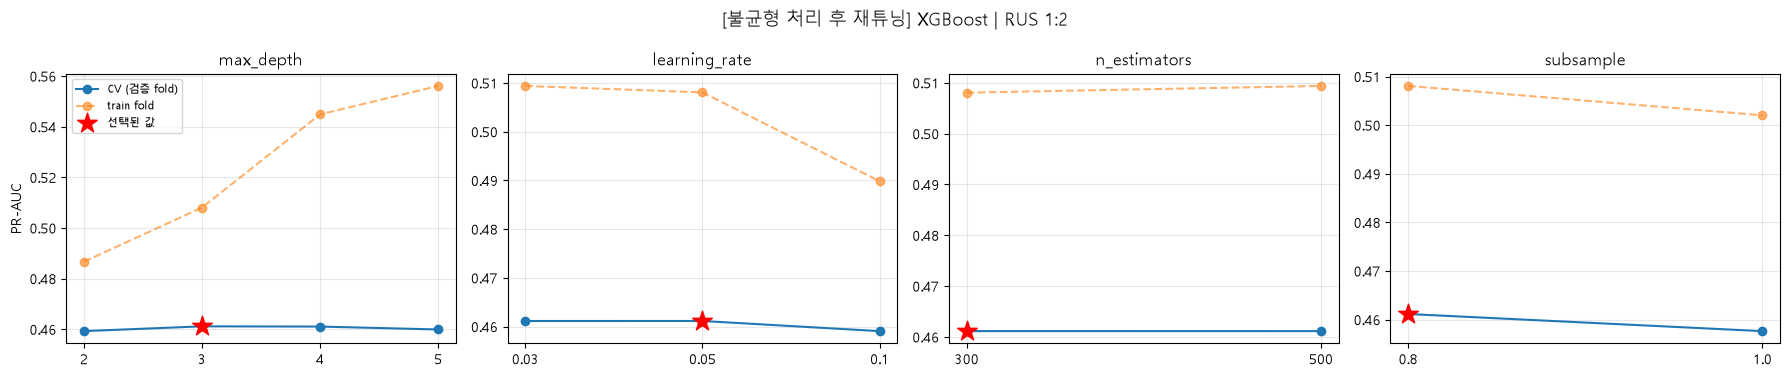

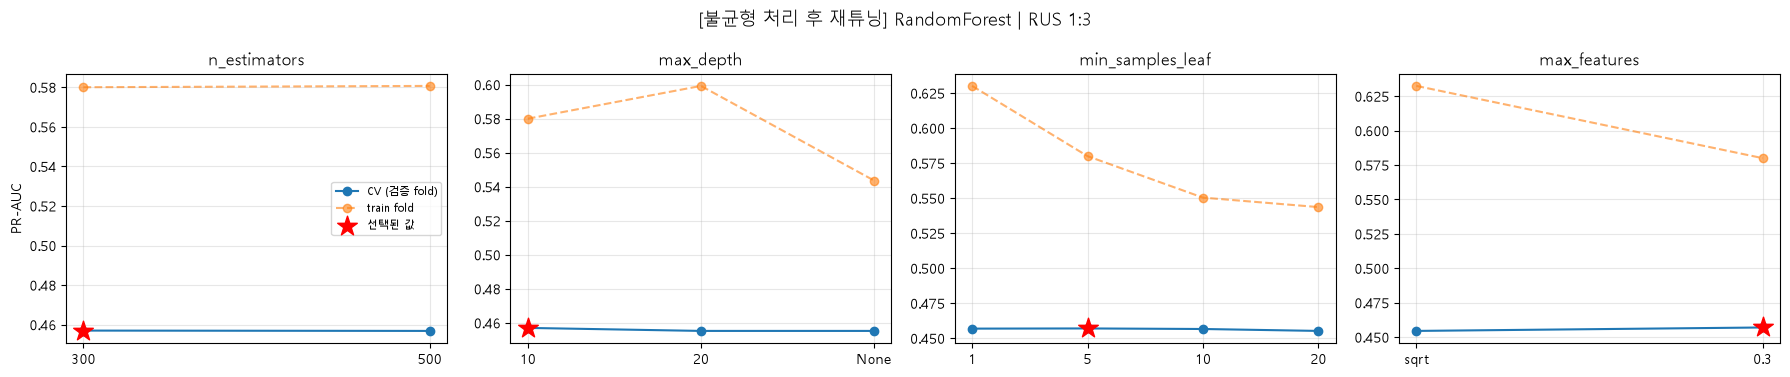

In [120]:
def plot_param_effect_tuned(search, title):
    """파라미터 값에 따라 CV PR-AUC가 어떻게 변하는지 파라미터마다 그래프 1개씩
    - ⑲는 여러 지표를 함께 기록했으므로 점수 컬럼 이름이 mean_test_pr_auc"""
    res = pd.DataFrame(search.cv_results_)
    grid = search.param_grid
    params = list(grid.keys())

    fig, axes = plt.subplots(1, len(params), figsize=(4.5 * len(params), 3.8), squeeze=False)

    for ax, p in zip(axes[0], params):
        labels = [str(v) for v in grid[p]]          # x축 라벨 (None도 'None'으로 표시)
        # 각 조합에서 이 파라미터가 어떤 값이었는지 (문자열로 통일해서 비교)
        col = pd.Series([str(d[p]) for d in search.cv_results_["params"]])

        # 값마다 '다른 파라미터를 가장 좋게 맞췄을 때'의 점수
        test_best, train_at = [], []
        for v in labels:
            mask = (col == v).values
            best_idx = res.loc[mask, "mean_test_pr_auc"].idxmax()
            test_best.append(res.loc[best_idx, "mean_test_pr_auc"])
            train_at.append(res.loc[best_idx, "mean_train_pr_auc"])

        x = np.arange(len(labels))
        ax.plot(x, test_best, marker="o", label="CV (검증 fold)")
        ax.plot(x, train_at, marker="o", ls="--", alpha=0.6, label="train fold")

        # 최종 선택된 값을 빨간 별로 표시
        bi = labels.index(str(search.best_params_[p]))
        ax.scatter(bi, test_best[bi], s=220, marker="*", color="red", zorder=5, label="선택된 값")

        ax.set_xticks(x)
        ax.set_xticklabels(labels)
        ax.set_title(clean_name(p))
        ax.grid(alpha=0.3)

    axes[0][0].set_ylabel("PR-AUC")
    axes[0][0].legend(fontsize=8)
    fig.suptitle(title, fontsize=13)
    fig.tight_layout()
    plt.show()


for (name, method), search in tuned_searches.items():
    plot_param_effect_tuned(search, f"[불균형 처리 후 재튜닝] {name} | {method.replace('SMOTENC', 'SMOTE')}")

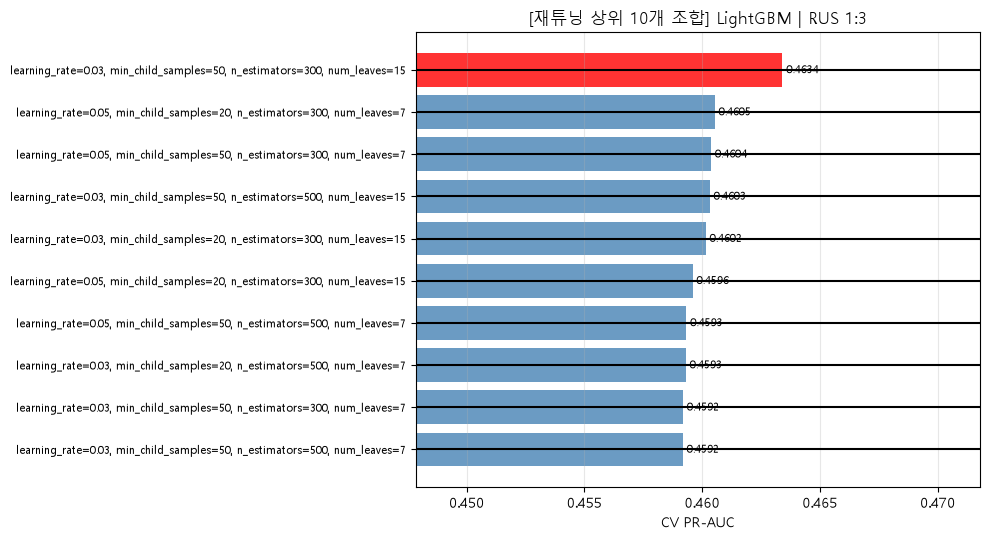

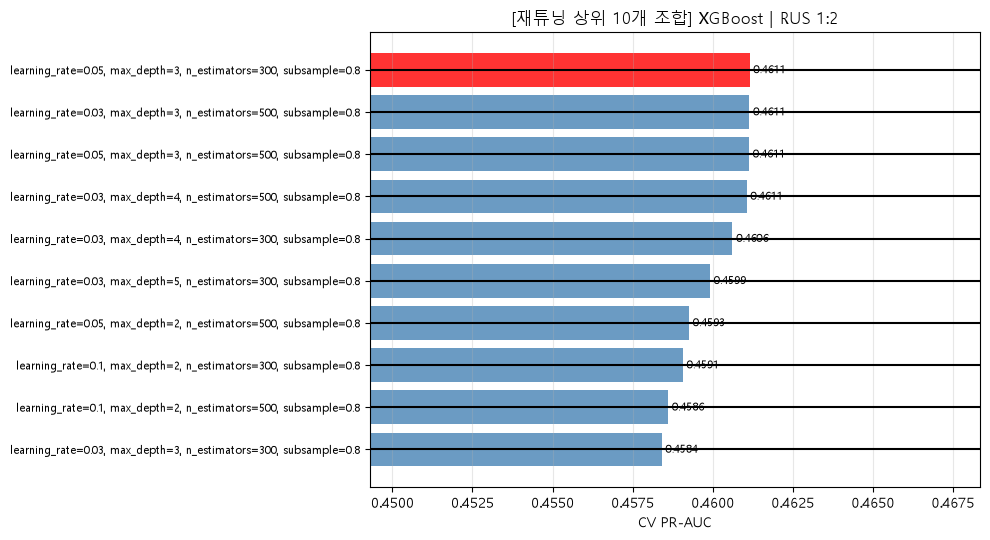

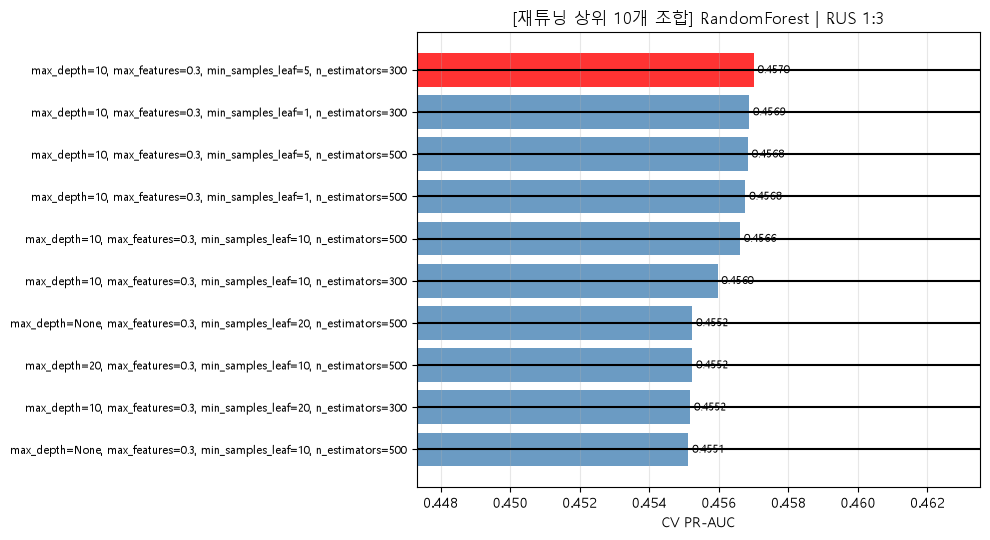

In [121]:
def plot_top_combos_tuned(search, title, top_n=10):
    """CV PR-AUC 상위 조합을 막대그래프로 (오차막대 = 5개 fold 간 표준편차)"""
    res = (pd.DataFrame(search.cv_results_)
           .sort_values("mean_test_pr_auc", ascending=False)
           .head(top_n))

    # y축 라벨: 'num_leaves=15, learning_rate=0.05' 형식
    labels = [", ".join(f"{clean_name(k)}={v}" for k, v in params.items())
              for params in res["params"]]

    fig, ax = plt.subplots(figsize=(10, 0.45 * len(res) + 1))
    colors = ["red"] + ["steelblue"] * (len(res) - 1)    # 1등(선택된 조합)만 빨간색
    ax.barh(range(len(res)), res["mean_test_pr_auc"], xerr=res["std_test_pr_auc"],
            color=colors, alpha=0.8, capsize=3)
    ax.set_yticks(range(len(res)))
    ax.set_yticklabels(labels, fontsize=8)
    ax.invert_yaxis()                                     # 1등이 맨 위로

    # 막대 끝에 점수 표시
    for i, v in enumerate(res["mean_test_pr_auc"]):
        ax.text(v, i, f" {v:.4f}", va="center", fontsize=8)

    # 점수 차이가 잘 보이도록 x축 범위를 상위 조합 근처로 좁힘
    lo, hi = res["mean_test_pr_auc"].min(), res["mean_test_pr_auc"].max()
    ax.set_xlim(lo - (hi - lo) * 1.5 - 0.005, hi + (hi - lo) * 0.8 + 0.005)
    ax.set_xlabel("CV PR-AUC")
    ax.set_title(title)
    ax.grid(axis="x", alpha=0.3)
    fig.tight_layout()
    plt.show()


for (name, method), search in tuned_searches.items():
    plot_top_combos_tuned(search, f"[재튜닝 상위 10개 조합] {name} | {method.replace('SMOTENC', 'SMOTE')}")

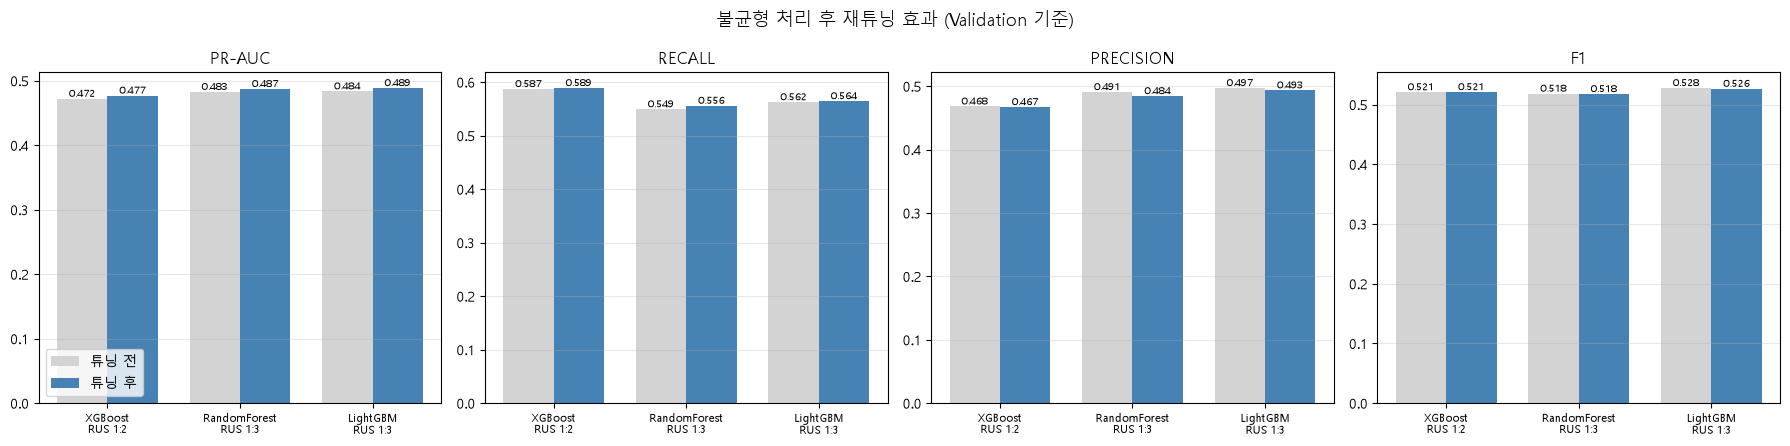

In [122]:
# ⑳의 compare 사용: 같은 조합의 튜닝 전(처리 전 파라미터 고정) vs 튜닝 후
metrics = ["pr_auc", "recall", "precision", "f1"]
combos = compare[["model", "method"]].drop_duplicates().values.tolist()
combo_labels = [f"{m}\n{meth.replace('SMOTENC', 'SMOTE')}" for m, meth in combos]

fig, axes = plt.subplots(1, len(metrics), figsize=(4.5 * len(metrics), 4.5))
width = 0.38

for ax, metric in zip(axes, metrics):
    x = np.arange(len(combos))
    for i, (stage, color) in enumerate([("튜닝 전", "lightgray"), ("튜닝 후", "steelblue")]):
        vals = [compare[(compare["model"] == m) & (compare["method"] == meth)
                        & (compare["구분"] == stage)][metric].iloc[0]
                for m, meth in combos]
        bars = ax.bar(x + (i - 0.5) * width, vals, width, label=stage, color=color)
        ax.bar_label(bars, fmt="%.3f", fontsize=7)        # 막대 위에 값 표시

    ax.set_xticks(x)
    ax.set_xticklabels(combo_labels, fontsize=8)
    ax.set_title(metric.upper().replace("_", "-"))
    ax.grid(axis="y", alpha=0.3)

axes[0].legend()
fig.suptitle("불균형 처리 후 재튜닝 효과 (Validation 기준)", fontsize=13)
fig.tight_layout()
plt.show()

In [126]:
# 어떤 지표로 튜닝 전/후, 그리고 최종 모델을 고를지
# - pr_auc: 임계값과 무관한 모델 자체의 실력 (튜닝 기준과 같음, 권장)
# - f1 등: 임계값 0.5 기준이라 ㉖에서 임계값을 바꾸면 달라지므로 참고용
SELECT_METRIC = "pr_auc"

final_rows = []
final_pool = {}    # (모델, 방법) → (학습된 모델, 튜닝 전/후)

for (name, method) in tuned_models:
    # ⑳의 compare에서 같은 조합의 튜닝 전/후 validation 점수
    pair = compare[(compare["model"] == name) & (compare["method"] == method)]
    before = pair[pair["구분"] == "튜닝 전"].iloc[0]
    after = pair[pair["구분"] == "튜닝 후"].iloc[0]

    if after[SELECT_METRIC] >= before[SELECT_METRIC]:
        # 튜닝 후가 같거나 더 좋으면 재튜닝한 모델 사용 (이미 train으로 학습된 상태)
        chosen_model, chosen, chosen_row = tuned_models[(name, method)], "튜닝 후", after
    else:
        # 튜닝 전이 더 좋으면 처리 전 파라미터로 만든 모델을 train으로 다시 학습
        chosen_model, fit_params = build_model(name, method)
        chosen_model.fit(X_train, y_train, **fit_params)
        chosen, chosen_row = "튜닝 전", before

    final_pool[(name, method)] = (chosen_model, chosen)
    final_rows.append({
        "model": name,
        "method": method,
        "선택": chosen,
        f"튜닝 전 {SELECT_METRIC}": before[SELECT_METRIC],
        f"튜닝 후 {SELECT_METRIC}": after[SELECT_METRIC],
        "선택 기준 점수": chosen_row[SELECT_METRIC],      # 선택된 쪽의 점수 (정렬 기준)
        "PR-AUC": chosen_row["pr_auc"],
        "Recall": chosen_row["recall"],
        "Precision": chosen_row["precision"],
        "F1": chosen_row["f1"],
    })

final_choice_table = (pd.DataFrame(final_rows)
                      .sort_values("선택 기준 점수", ascending=False)   # 가장 좋은 조합이 맨 위
                      .set_index(["model", "method"])
                      .round(4))
print(f"[조합별 튜닝 전/후 선택 ({SELECT_METRIC} 기준, Validation)]")
display(final_choice_table)

# 최종 모델: 위 표에서 맨 위(가장 좋은) 조합
FINAL_KEY = final_choice_table.index[0]
# 직접 고르고 싶으면 위 줄 대신 아래처럼 지정
# FINAL_KEY = ("LightGBM", "RUS 1:3")

final_model, final_version = final_pool[FINAL_KEY]
print(f"\n▶ 최종 모델: {FINAL_KEY[0]} | {FINAL_KEY[1]} ({final_version})")

[조합별 튜닝 전/후 선택 (pr_auc 기준, Validation)]


,,선택,튜닝 전 pr_auc,튜닝 후 pr_auc,선택 기준 점수,PR-AUC,Recall,Precision,F1
model,method,,,,,,,,
LightGBM,RUS 1:3,튜닝 후,0.4835,0.4887,0.4887,0.4887,0.5643,0.4934,0.5265
RandomForest,RUS 1:3,튜닝 후,0.4827,0.4872,0.4872,0.4872,0.5558,0.4843,0.5176
XGBoost,RUS 1:2,튜닝 후,0.4720,0.4769,0.4769,0.4769,0.5888,0.4670,0.5209



▶ 최종 모델: LightGBM | RUS 1:3 (튜닝 후)


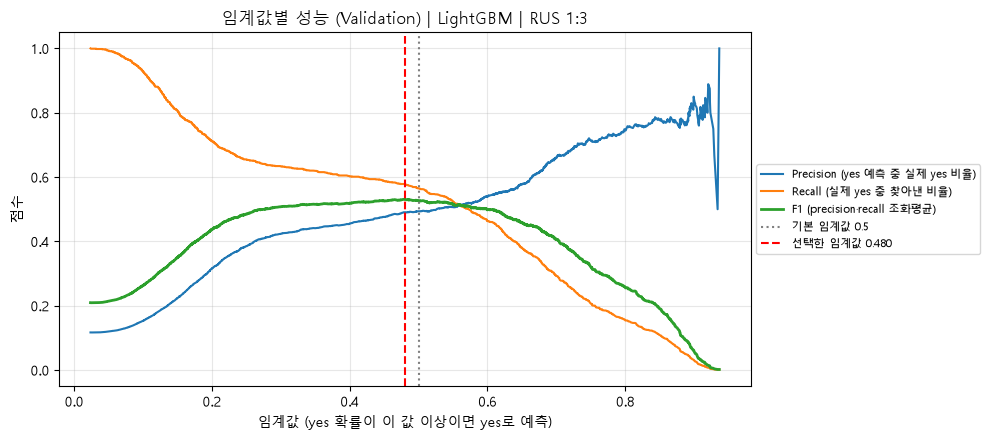

[임계값 비교 (Validation)]


,Accuracy,Precision,Recall,F1,PR-AUC,ROC-AUC,TP,FP,FN,TN
임계값 0.5,0.8812,0.4934,0.5643,0.5265,0.4887,0.8172,597.0,613.0,461.0,7371.0
임계값 0.480,0.8806,0.4912,0.5784,0.5312,0.4887,0.8172,612.0,634.0,446.0,7350.0


In [127]:
# 임계값 결정 방식
# - "f1": F1이 가장 높은 임계값 (precision과 recall의 균형)
# - "recall": recall이 목표(MIN_RECALL) 이상인 임계값 중 precision이 가장 높은 것
#             (가입 고객을 일정 비율 이상 놓치지 않는 게 우선일 때)
THRESHOLD_RULE = "f1"
MIN_RECALL = 0.70

# validation 예측 확률
proba_val = final_model.predict_proba(X_val)[:, 1]

# 가능한 모든 임계값에서 precision, recall 계산
# (precision, recall은 임계값보다 1개 더 길어서 마지막 값을 잘라 길이를 맞춤)
prec, rec, thr = precision_recall_curve(y_val, proba_val)
prec, rec = prec[:-1], rec[:-1]
f1s = np.where(prec + rec > 0, 2 * prec * rec / (prec + rec), 0)

if THRESHOLD_RULE == "f1":
    best_i = np.argmax(f1s)
else:
    ok = np.where(rec >= MIN_RECALL)[0]          # recall 목표를 만족하는 임계값들
    best_i = ok[np.argmax(prec[ok])]             # 그중 precision이 가장 높은 것
BEST_THRESHOLD = thr[best_i]

# 그래프: 임계값에 따른 precision / recall / F1 변화
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(thr, prec, label="Precision (yes 예측 중 실제 yes 비율)")
ax.plot(thr, rec, label="Recall (실제 yes 중 찾아낸 비율)")
ax.plot(thr, f1s, label="F1 (precision·recall 조화평균)", lw=2)
ax.axvline(0.5, color="gray", ls=":", label="기본 임계값 0.5")
ax.axvline(BEST_THRESHOLD, color="red", ls="--", label=f"선택한 임계값 {BEST_THRESHOLD:.3f}")
ax.set_xlabel("임계값 (yes 확률이 이 값 이상이면 yes로 예측)")
ax.set_ylabel("점수")
ax.set_title(f"임계값별 성능 (Validation) | {FINAL_KEY[0]} | {FINAL_KEY[1]}")
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1, 0.5))   # 그래프 오른쪽 바깥에 범례
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()


def threshold_metrics(y_true, proba, threshold):
    """주어진 임계값으로 yes/no를 나눴을 때의 지표"""
    pred = (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "PR-AUC": average_precision_score(y_true, proba),   # 임계값과 무관
        "ROC-AUC": roc_auc_score(y_true, proba),            # 임계값과 무관
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    }


# 기본 0.5와 선택한 임계값 비교 (validation)
th_table = pd.DataFrame({
    "임계값 0.5": threshold_metrics(y_val, proba_val, 0.5),
    f"임계값 {BEST_THRESHOLD:.3f}": threshold_metrics(y_val, proba_val, BEST_THRESHOLD),
}).T.round(4)
print("[임계값 비교 (Validation)]")
display(th_table)

In [128]:
#   test 결과를 보고 모델이나 임계값을 다시 바꾸면 test가 validation처럼 오염되어
#   더 이상 '처음 보는 데이터에서의 성능'이라고 말할 수 없음

# test 예측 확률 (모델은 train으로만 학습된 상태 그대로)
proba_test = final_model.predict_proba(X_test)[:, 1]

# validation vs test 비교: 비슷하면 validation에 과적합되지 않았다는 근거
final_table = pd.DataFrame({
    "Validation": threshold_metrics(y_val, proba_val, BEST_THRESHOLD),
    "Test": threshold_metrics(y_test, proba_test, BEST_THRESHOLD),
}).T.round(4)

print(f"[최종 모델: {FINAL_KEY[0]} | {FINAL_KEY[1]} ({final_version}) | 임계값 {BEST_THRESHOLD:.3f}]")
display(final_table)

# test 혼동행렬
pred_test = (proba_test >= BEST_THRESHOLD).astype(int)
cm_test = pd.DataFrame(confusion_matrix(y_test, pred_test),
                       index=["실제 no", "실제 yes"],
                       columns=["예측 no", "예측 yes"])
print(f"\n[Test 혼동행렬 | 실제 yes = {(y_test == 1).sum()}명]")
display(cm_test)

[최종 모델: LightGBM | RUS 1:3 (튜닝 후) | 임계값 0.480]


,Accuracy,Precision,Recall,F1,PR-AUC,ROC-AUC,TP,FP,FN,TN
Validation,0.8806,0.4912,0.5784,0.5312,0.4887,0.8172,612.0,634.0,446.0,7350.0
Test,0.8799,0.4884,0.5558,0.5199,0.4852,0.8163,588.0,616.0,470.0,7369.0



[Test 혼동행렬 | 실제 yes = 1058명]


,예측 no,예측 yes
실제 no,7369,616
실제 yes,470,588
